# تحلیل شاخص‌های کلان جمعیتی، نیروی کار و آموزش ایران

مینی‌پروژه‌ی تحلیل داده با پایتون (pandas و matplotlib)

## درباره‌ی پروژه

در این نوت‌بوک داده‌های فایل اکسل «شاخص‌های کلان» (شیت «جمعیت و نیروی انسانی») خوانده، پاک‌سازی و تحلیل می‌شود. این شیت شامل ۱۵ جدول است که زیر هم قرار گرفته‌اند؛ جدول‌ها به‌صورت خودکار شناسایی و جدا می‌شوند، سپس برای هر جدول نرخ رشد سالانه محاسبه و نمودار رسم می‌شود.

## ساختار نوت‌بوک

1. تنظیم نمایش فونت فارسی در نمودارها
2. کتابخانه‌ها
3. توابع کمکی
4. بارگذاری داده و شناسایی خودکار جدول‌ها
5. تحلیل داده، در سه بخش: جمعیت و شاخص‌های جمعیتی، نیروی کار، آموزش

# تنظیم نمایش فونت فارسی در مت پلات لیب

In [ ]:
pip install arabic-reshaper python-bidi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 11.8 MB/s eta 0:00:00


In [ ]:
import arabic_reshaper
from bidi.algorithm import get_display

def fix_persian_text(text):
    """
    متن فارسی را برای نمایش صحیح در matplotlib آماده می‌کند.
    """
    if not isinstance(text, str):
        return text
    # 1. شکل‌دهی حروف عربی/فارسی (اتصال حروف)
    reshaped_text = arabic_reshaper.reshape(text)
    # 2. معکوس کردن جهت متن (از چپ به راست به راست به چپ)
    bidirectional_text = get_display(reshaped_text)
    return bidirectional_text

# کتابخانه‌ها

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
# روش جایگزین سریع (اگر فونت وزیرمتن نصب نیست)
import matplotlib.ticker as ticker
# تلاش برای استفاده از فونت‌های موجود در سیستم که فارسی دارند
plt.rcParams['font.sans-serif'] = ['Tahoma', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# جلوگیری از نمایش منفی (-) به صورت مربع
plt.rcParams['axes.unicode_minus'] = False
import warnings
warnings.filterwarnings('ignore')


pd.reset_option('display.float_format')
pd.options.display.float_format = '{:.3f}'.format

# توابع کمکی

همه‌ی توابع پروژه در همین بخش تعریف شده‌اند و در بخش‌های بعدی فقط فراخوانی می‌شوند. توابع در سه گروه قرار دارند: استخراج و پاک‌سازی جدول‌ها، محاسبه‌ی نرخ رشد، و رسم نمودار.

## توابع استخراج و پاک‌سازی

- `extract_table`: بلوک یک جدول را از دیتافریم خام جدا می‌کند و عنوان و بدنه‌ی آن را برمی‌گرداند.
- `clean_and_rename`: سطرهای هدر اضافی را حذف و نام ستون‌ها را تنظیم می‌کند.
- `parse_higher_edu_table`: جدول‌های آموزش عالی را به دو بخش «سری زمانی سالانه» و «تفکیک گروه رشته» تقسیم می‌کند.
- `load_yearly_table`: استخراج و پاک‌سازی کامل یک جدول سالانه (جدول‌های ۵ تا ۱۲) در یک گام.
- `to_numeric_or_keep`: ستون را عددی می‌کند و اگر نشد، همان را برمی‌گرداند.

In [ ]:
def extract_table(df, start, end):
    """
    استخراج خام یک بلوک جدول از دیتافریم اصلی
    """
    # 1. استخراج زیر-دیتافریم
    sub = df.iloc[start : end + 1]

    # 2. گرفتن عنوان (از سطر اول، ستون اول)
    title = sub.iloc[0, 0]

    # 3. ساخت بدنه داده (حذف سطر عنوان)
    body = sub.iloc[1:, :]

    # 4. حذف ستون آخر ONLY اگر تمام مقادیر آن NaN (خالی) باشند
    # این کار از حذف اشتباه داده‌های واقعی جلوگیری می‌کند
    if body.shape[1] > 1 and body.iloc[:, -1].isna().all():
        body = body.iloc[:, :-1]

    # 5. ریست اندیس
    body.reset_index(drop=True, inplace=True)

    return title, body


In [ ]:
def clean_and_rename(body, drop_rows, new_cols):
    """
    پاکسازی بدنه جدول و تنظیم نام ستون‌ها
    :param body: دیتافریم خام (خروجی extract_table)
    :param drop_rows: لیست شماره سطرهایی که باید حذف شوند (مثلا [1, 2])
    :param new_cols: لیست نام ستون‌های جدید
    """
    # 1. حذف سطرهای هدر اضافی
    cleaned_body = body.drop(index=drop_rows)

    # 2. ریست اندیس برای تمیزی
    cleaned_body.reset_index(drop=True, inplace=True)

    # 3. تنظیم نام ستون‌ها
    cleaned_body.columns = new_cols

    return cleaned_body

In [ ]:
def load_yearly_table(df, start, end, cols, header_rows, year_range=None):
    """
    استخراج و پاک‌سازی کامل یک جدول سالانه (جدول‌های ۵ تا ۱۲):
      1. استخراج بلوک جدول و گرفتن عنوان
      2. نگه داشتن فقط ستون‌های واقعی (بقیه‌ی ستون‌ها خالی‌اند)
      3. حذف سطرهای هدر و نام‌گذاری ستون‌ها
      4. عددی کردن مقادیر؛ ردیف‌های فصلی (مثل «بهار 1404») در ستون سال NaN می‌شوند و کنار می‌روند
      5. در صورت دادن year_range=(از, تا)، فقط همان سال‌ها نگه داشته می‌شوند
    خروجی: (عنوان جدول، دیتافریم تمیز)
    """
    title, body = extract_table(df, start, end)
    body = body.iloc[:, :len(cols)]
    out = clean_and_rename(body, drop_rows=list(range(header_rows)), new_cols=cols)

    out = out.apply(pd.to_numeric, errors='coerce')
    out = out.dropna(subset=['سال']).reset_index(drop=True)
    out['سال'] = out['سال'].astype(int)

    if year_range is not None:
        first, last = year_range
        out = out[(out['سال'] >= first) & (out['سال'] <= last)].reset_index(drop=True)
    return title, out

In [ ]:
def to_numeric_or_keep(col):
    """
    ستون را عددی می‌کند؛ اگر نشد، ستون اصلی را بدون تغییر برمی‌گرداند.
    (جایگزین pd.to_numeric(..., errors='ignore') که در نسخه‌های جدید pandas حذف شده است.)
    """
    try:
        return pd.to_numeric(col)
    except (ValueError, TypeError):
        return col

In [ ]:
def parse_higher_edu_table(df, start, end):
    """
    جدول را به دو بخش تقسیم می‌کند:
      series_df : سری زمانی (ستون‌ها: سال [سال شروع]، کل، مرد، زن)
      fields_df : تفکیک گروه رشته برای آخرین سال جدول (ستون‌ها: گروه، کل، مرد، زن)
    و عنوان جدول و برچسب آخرین سال (مثل 1403-1404) را هم برمی‌گرداند.
    """
    # ۱. استخراج و نام‌گذاری (ستون اول «سال و دوره تحصیلی» می‌شود «سال»)
    title, body = extract_table(df, start=start, end=end)
    body = body.iloc[:, :4]
    raw = clean_and_rename(body, drop_rows=[0], new_cols=['سال', 'کل', 'مرد', 'زن'])
    raw[['کل', 'مرد', 'زن']] = raw[['کل', 'مرد', 'زن']].apply(pd.to_numeric)

    # ۲. جدا کردن ردیف‌های سال (دارای «-») از ردیف‌های گروه رشته
    is_year = raw['سال'].astype(str).str.contains('-')
    series_df = raw[is_year].copy()
    fields_df = raw[~is_year].copy().rename(columns={'سال': 'گروه'}).reset_index(drop=True)

    # ۳. فقط سال شروع را نگه می‌داریم
    last_label = series_df['سال'].iloc[-1]                 # مثلاً 1403-1404
    series_df['سال'] = series_df['سال'].str.split('-').str[0].astype(int)
    series_df = series_df.reset_index(drop=True)

    # ۴. کنترل: جمع گروه‌های رشته باید برابر آخرین سال جدول باشد
    if fields_df['کل'].sum() != series_df['کل'].iloc[-1]:
        print('⚠️ جمع گروه‌های رشته با آخرین سال جدول برابر نیست!')

    return title, series_df, fields_df, last_label

## توابع محاسبه‌ی نرخ رشد

- `calculate_growth_rates_multi`: نرخ رشد درصدی برای هر تعداد ستون (تابع پایه).
- `calculate_growth_rates`: نرخ رشد درصدی سه متغیر (کل، مرد، زن).
- `calculate_growth_rates_two`: نرخ رشد درصدی دو متغیر (مثل ازدواج و طلاق).

In [ ]:
def calculate_growth_rates_multi(df, cols, out_names):
    """
    محاسبه نرخ رشد درصدی برای هر تعداد ستون
    cols: نام ستون‌ها در df ، out_names: نام ستون‌های خروجی
    (سطر اول به‌خاطر pct_change مقدار ندارد و حذف می‌شود)
    """
    result = pd.DataFrame({'سال': df['سال'][1:].values})
    for col, out in zip(cols, out_names):
        result[out] = (df[col].pct_change() * 100)[1:].values
    return result

In [ ]:
def calculate_growth_rates(df, col_total, col_men, col_women,
                           out_total='نرخ_رشد_کل',
                           out_men='نرخ_رشد_مرد',
                           out_women='نرخ_رشد_زن'):
    """
    محاسبه نرخ رشد درصدی برای سه متغیر (کل، مرد، زن)
    """
    return calculate_growth_rates_multi(
        df,
        cols=[col_total, col_men, col_women],
        out_names=[out_total, out_men, out_women],
    )

In [ ]:
def calculate_growth_rates_two(df, col_a, col_b, out_a, out_b):
    """
    محاسبه نرخ رشد درصدی برای دو متغیر (مثل ازدواج و طلاق)
    """
    return calculate_growth_rates_multi(df, cols=[col_a, col_b], out_names=[out_a, out_b])

## توابع رسم نمودار

- `plot_combined_chart`: میله‌ی مقدار خام و سه خط نرخ رشد (کل، مرد، زن).
- `plot_two_series_chart`: دو میله‌ی کنار هم و دو خط نرخ رشد.
- `plot_multi_growth_chart`: میله‌ی مقدار خام و چند خط نرخ رشد.
- `plot_rate_lines`: نمودار خطی چند شاخص درصدی روی یک محور.
- `plot_region_rates`: نمودار خطی کل کشور / نقاط شهری / نقاط روستایی با ظاهر ثابت.
- `plot_birth_vs_death_comparison`: مقایسه‌ی ولادت و وفات در سه زیرنمودار (کل کشور، شهری، روستایی).
- `plot_field_breakdown`: میله‌ی افقی انباشته‌ی گروه رشته و جنسیت، با درصد زنان کنار هر میله.

In [ ]:
def plot_combined_chart(df_growth, df_raw, col_raw_total,
                        col_rate_total, col_rate_men, col_rate_women,
                        title_text, label_bar, label_line_total, label_line_men, label_line_women):
    """
    رسم نمودار ترکیبی (میله‌ای + ۳ خط روند)
    """
    fig, ax1 = plt.subplots(figsize=(11, 5))

    # 1. نمودار میله‌ای (مقادیر خام مثل جمعیت یا تعداد تولد)
    # توجه: چون df_growth سطر اول را ندارد (به خاطر pct_change)، از df_raw[1:] استفاده می‌کنیم
    bars = ax1.bar(df_growth['سال'], df_raw[col_raw_total][1:],
                   color='lightblue', alpha=0.6, label=fix_persian_text(label_bar))

    ax1.set_xlabel(fix_persian_text('سال'), fontsize=12)
    ax1.set_ylabel(fix_persian_text('مقدار'), color='steelblue', fontsize=12)
    ax1.tick_params(axis='y', labelcolor='steelblue')
    plt.xticks(rotation=45)

    # 2. نمودارهای خطی (نرخ‌های رشد)
    ax2 = ax1.twinx()

    line_total, = ax2.plot(df_growth['سال'], df_growth[col_rate_total],
                           marker='o', color='red', linewidth=2, markersize=5,
                           label=fix_persian_text(label_line_total))

    line_men, = ax2.plot(df_growth['سال'], df_growth[col_rate_men],
                         marker='s', color='darkgreen', linewidth=2, markersize=5, linestyle='--',
                         label=fix_persian_text(label_line_men))

    line_women, = ax2.plot(df_growth['سال'], df_growth[col_rate_women],
                           marker='^', color='purple', linewidth=2, markersize=5, linestyle=':',
                           label=fix_persian_text(label_line_women))

    ax2.set_ylabel(fix_persian_text('نرخ تغییرات (%)'), color='black', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='black')

    # 3. عنوان و Legend
    plt.title(fix_persian_text(title_text), fontsize=14, fontweight='bold', pad=20)

    handles = [bars, line_total, line_men, line_women]
    labels = [h.get_label() for h in handles]
    ax1.legend(handles, labels, loc='upper right', frameon=True, shadow=True)

    ax1.grid(True, linestyle='--', alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_two_series_chart(df_growth, df_raw, col_raw_a, col_raw_b,
                          col_rate_a, col_rate_b, title_text,
                          label_bar_a, label_bar_b, label_line_a, label_line_b):
    """
    رسم نمودار ترکیبی (۲ میله‌ی کنار هم + ۲ خط نرخ رشد)
    """
    fig, ax1 = plt.subplots(figsize=(11, 5))

    x = np.arange(len(df_growth))
    w = 0.38

    # میله‌ها: مقادیر خام (چون سطر اول نرخ رشد ندارد از [1:] استفاده می‌کنیم)
    bars_a = ax1.bar(x - w/2, df_raw[col_raw_a][1:].values, w, color='lightblue',
                     alpha=0.8, label=fix_persian_text(label_bar_a))
    bars_b = ax1.bar(x + w/2, df_raw[col_raw_b][1:].values, w, color='moccasin',
                     alpha=0.8, label=fix_persian_text(label_bar_b))

    ax1.set_xticks(x)
    ax1.set_xticklabels(df_growth['سال'], rotation=45)
    ax1.set_xlabel(fix_persian_text('سال'), fontsize=12)
    ax1.set_ylabel(fix_persian_text('تعداد'), color='steelblue', fontsize=12)
    ax1.tick_params(axis='y', labelcolor='steelblue')
    ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))

    # خطوط: نرخ رشد
    ax2 = ax1.twinx()
    line_a, = ax2.plot(x, df_growth[col_rate_a], marker='o', color='red', linewidth=2,
                       markersize=5, label=fix_persian_text(label_line_a))
    line_b, = ax2.plot(x, df_growth[col_rate_b], marker='s', color='darkgreen', linewidth=2,
                       markersize=5, linestyle='--', label=fix_persian_text(label_line_b))
    ax2.axhline(0, color='gray', linewidth=0.8, linestyle=':')
    ax2.set_ylabel(fix_persian_text('نرخ تغییرات (%)'), color='black', fontsize=12)

    plt.title(fix_persian_text(title_text), fontsize=14, fontweight='bold', pad=20)

    handles = [bars_a, bars_b, line_a, line_b]
    labels = [h.get_label() for h in handles]
    ax1.legend(handles, labels, loc='upper right', frameon=True, shadow=True)

    ax1.grid(True, linestyle='--', alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_multi_growth_chart(df_growth, df_raw, col_raw_total, rate_cols, labels_lines,
                            title_text, label_bar):
    """
    رسم نمودار ترکیبی (میله‌ی مقدار خام + چند خط نرخ رشد)
    """
    fig, ax1 = plt.subplots(figsize=(11, 5))

    bars = ax1.bar(df_growth['سال'], df_raw[col_raw_total][1:], color='lightblue',
                   alpha=0.6, label=fix_persian_text(label_bar))
    ax1.set_xlabel(fix_persian_text('سال'), fontsize=12)
    ax1.set_ylabel(fix_persian_text('مقدار (هزار نفر)'), color='steelblue', fontsize=12)
    ax1.tick_params(axis='y', labelcolor='steelblue')
    ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax1.set_xticks(df_growth['سال'])
    plt.xticks(rotation=45)

    ax2 = ax1.twinx()
    styles = [('red', 'o', '-'), ('darkgreen', 's', '--'), ('purple', '^', ':'), ('darkorange', 'D', '-.')]
    handles = [bars]
    for col, lab, (color, mk, ls) in zip(rate_cols, labels_lines, styles):
        line, = ax2.plot(df_growth['سال'], df_growth[col], marker=mk, color=color, linewidth=2,
                         markersize=5, linestyle=ls, label=fix_persian_text(lab))
        handles.append(line)
    ax2.axhline(0, color='gray', linewidth=0.8, linestyle=':')
    ax2.set_ylabel(fix_persian_text('نرخ تغییرات (%)'), fontsize=12)

    plt.title(fix_persian_text(title_text), fontsize=14, fontweight='bold', pad=20)
    ax1.legend(handles, [h.get_label() for h in handles], loc='lower right', frameon=True, facecolor='white', framealpha=0.3, edgecolor='lightgray')
    ax1.grid(True, linestyle='--', alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_rate_lines(df, cols, labels, styles, title_text, ylabel='درصد'):
    """
    رسم نمودار خطی چند شاخص درصدی در یک محور
    """
    fig, ax = plt.subplots(figsize=(11, 5))
    for col, lab, (color, mk, ls) in zip(cols, labels, styles):
        ax.plot(df['سال'], df[col], marker=mk, color=color, linewidth=2, markersize=5,
                linestyle=ls, label=fix_persian_text(lab))
        ax.annotate(f"{df[col].iloc[-1]:.1f}", (df['سال'].iloc[-1], df[col].iloc[-1]),
                    textcoords='offset points', xytext=(8, 0), fontsize=9)
    ax.set_xticks(df['سال'])
    ax.set_xlabel(fix_persian_text('سال'), fontsize=12)
    ax.set_ylabel(fix_persian_text(ylabel), fontsize=12)
    ax.set_title(fix_persian_text(title_text), fontsize=14, fontweight='bold', pad=15)
    ax.legend(frameon=True, shadow=True)
    ax.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_region_rates(df, title_text):
    """
    نمودار خطی «کل کشور / نقاط شهری / نقاط روستایی» با ظاهر ثابت
    (پوشش‌دهنده‌ی plot_rate_lines برای جدول‌هایی که همین سه ستون را دارند)
    """
    plot_rate_lines(
        df, ['کل_کشور', 'نقاط_شهری', 'نقاط_روستایی'],
        ['کل کشور', 'نقاط شهری', 'نقاط روستایی'],
        [('red', 'o', '-'), ('steelblue', 's', '--'), ('darkorange', '^', ':')],
        title_text
    )

In [ ]:
def plot_birth_vs_death_comparison(df):
  fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

  categories = [
      ('کل کشور', 'ولادت_کل', 'وفات_کل', axes[0]),
      ('مناطق شهری', 'ولادت_شهری', 'وفات_شهری', axes[1]),
      ('مناطق روستایی', 'ولادت_روستایی', 'وفات_روستایی', axes[2]),
  ]

  for title, col_b, col_d, ax in categories:
    ax.plot(
        df['سال'],
        df[col_b],
        marker='o',
        color='green',
        linewidth=2.5,
        label=fix_persian_text(f'تعداد ولادت ({title})'),
    )
    ax.plot(
        df['سال'],
        df[col_d],
        marker='s',
        color='red',
        linewidth=2.5,
        linestyle='--',
        label=fix_persian_text(f'تعداد وفات ({title})'),
    )

    ax.set_title(
        fix_persian_text(f'مقایسه روند ولادت و وفات در {title}'),
        fontsize=12,
        fontweight='bold',
    )
    ax.set_ylabel(fix_persian_text('تعداد (نفر)'), fontsize=10)

    # جلوگیری از نمایش اعداد به صورت نماد علمی و استفاده از جداکننده هزارگان
    formatter = ticker.ScalarFormatter(useOffset=False)
    formatter.set_scientific(False)
    ax.yaxis.set_major_formatter(formatter)

    ax.legend(loc='upper right', frameon=True, shadow=True)
    ax.grid(True, linestyle='--', alpha=0.3)

  plt.xlabel(fix_persian_text('سال شمسی'), fontsize=12)
  plt.tight_layout()
  plt.show()

In [ ]:
def plot_field_breakdown(fields_df, year_label, title_text):
    """
    نمودار میله‌ای افقی انباشته: طول میله = تعداد کل گروه، رنگ‌ها = سهم مرد و زن.
    عدد کنار هر میله = درصد زنان.
    """
    d = fields_df.sort_values('کل').reset_index(drop=True)     # بزرگ‌ترین بالای نمودار
    y = np.arange(len(d))
    women_share = d['زن'] / d['کل'] * 100

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.barh(y, d['مرد'], color='steelblue', alpha=0.85, label=fix_persian_text('مرد'))
    ax.barh(y, d['زن'], left=d['مرد'], color='lightcoral', alpha=0.85, label=fix_persian_text('زن'))

    for yi, total, share in zip(y, d['کل'], women_share):
        ax.text(total, yi, f'  {share:.0f}%', va='center', fontsize=10)

    ax.set_yticks(y)
    ax.set_yticklabels([fix_persian_text(g) for g in d['گروه']], fontsize=11)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_xlabel(fix_persian_text('تعداد (عدد کنار هر میله: درصد زنان)'), fontsize=12)
    ax.set_title(fix_persian_text(f'{title_text} ({year_label})'), fontsize=14, fontweight='bold', pad=15)
    ax.set_xlim(0, d['کل'].max() * 1.12)
    ax.legend(loc='lower right', frameon=True, shadow=True)
    ax.grid(True, axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()


# بارگذاری داده

فایل اکسل شاخص‌های کلان از مسیر زیر خوانده می‌شود. همه‌ی جدول‌ها زیر هم در یک شیت (`جمعیت و نیروی انسانی`) قرار دارند؛ برای همین فایل ابتدا بدون هدر (`header=None`) خوانده می‌شود و در ادامه جدول‌ها از هم جدا می‌شوند.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = '/content/drive/MyDrive/ne_shakhes_kalan_1405_05-14050524133406.xlsx'

In [ ]:
df = pd.read_excel(path, sheet_name='جمعیت و نیروی انسانی', header=None)
print(df.shape)
display(df.head())

(294, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,پیش‌بینی جمعیت کل کشور به تفکیک جنس، مناطق شهر...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,سال,کل کشور,NaN,NaN,مناطق شهری,NaN,NaN,مناطق روستایی و غیرساکن,NaN,NaN,NaN
2,NaN,کل,مرد,زن,کل,مرد,زن,کل,مرد,زن,NaN
3,1396,81053,41040,40013,60304,30529,29775,20749,10511,10238,NaN
4,1397,81962,41476,40487,61311,31021,30290,20652,10455,10197,NaN


## شناسایی خودکار جدول‌ها

هر جدول با ردیفی که شامل واژه‌ی «مأخذ» است پایان می‌یابد. بر همین اساس ردیف شروع و پایان همه‌ی جدول‌ها پیدا و در `tables_info` ذخیره می‌شود.

In [ ]:
# ۲. شناسایی خودکار بازه و محدوده شروع و پایان جدول‌ها بر اساس کلمه کلیدی مأخذ
mask = df.iloc[:, 0].str.contains("ماخذ|مأخذ", na=False)
maakhaz_indices = list(mask.index[mask])

# ساخت خودکار بازه‌ها (شروع و پایان)
end_rows = [idx - 1 for idx in maakhaz_indices]
start_rows = [0] + [idx + 2 for idx in maakhaz_indices[:-1]]
tables_info = list(zip(start_rows, end_rows))

print(f"تعداد کل جدول‌های شناسایی شده در فایل: {len(tables_info)}")
for i, (start, end) in enumerate(tables_info):
    print(f"   - جدول {i+1}: از ردیف {start} تا {end}")

تعداد کل جدول‌های شناسایی شده در فایل: 15
   - جدول 1: از ردیف 0 تا 22
   - جدول 2: از ردیف 25 تا 29
   - جدول 3: از ردیف 32 تا 49
   - جدول 4: از ردیف 52 تا 69
   - جدول 5: از ردیف 72 تا 88
   - جدول 6: از ردیف 91 تا 107
   - جدول 7: از ردیف 110 تا 127
   - جدول 8: از ردیف 130 تا 147
   - جدول 9: از ردیف 150 تا 167
   - جدول 10: از ردیف 170 تا 187
   - جدول 11: از ردیف 190 تا 207
   - جدول 12: از ردیف 210 تا 226
   - جدول 13: از ردیف 229 تا 253
   - جدول 14: از ردیف 256 تا 273
   - جدول 15: از ردیف 276 تا 292


# تحلیل داده

هر جدول از شیت جدا و پاک‌سازی می‌شود، سپس (در جایی که معنا دارد) نرخ رشد سالانه محاسبه و نمودار رسم می‌شود. تحلیل‌ها در سه بخش آمده است: جمعیت و شاخص‌های جمعیتی، نیروی کار، و آموزش.

## الف) جمعیت و شاخص‌های جمعیتی (جدول‌های ۱ تا ۵)

### جدول ۱: پیش‌بینی جمعیت کل کشور به تفکیک جنس و مناطق شهری و روستایی (هزار نفر)

In [ ]:
# ۳. استخراج و تمیزکاری ساختاریافته جدول ۱
title_1, body_1 = extract_table(df, *tables_info[0])

cols_population = [
    'سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور',
    'شهر_کل', 'مرد_شهر', 'زن_شهر',
    'کل_روستا', 'مرد_روستا', 'زن_روستا'
]

population_df = clean_and_rename(body_1, drop_rows=[0, 1], new_cols=cols_population)
population_df = population_df.apply(pd.to_numeric, errors='coerce').fillna(0).astype('int64')

print(f"عنوان جدول ۱: {title_1}")
display(population_df.head())

عنوان جدول ۱: پیش‌بینی جمعیت کل کشور به تفکیک جنس، مناطق شهری و روستایی و غیرساکن     (هزار نفر)


,سال,کل_کشور,مرد_کشور,زن_کشور,شهر_کل,مرد_شهر,زن_شهر,کل_روستا,مرد_روستا,زن_روستا
0,1396,81053,41040,40013,60304,30529,29775,20749,10511,10238
1,1397,81962,41476,40487,61311,31021,30290,20652,10455,10197
2,1398,82710,41831,40880,62201,31454,30748,20509,10377,10132
3,1399,83409,42162,41247,63056,31869,31187,20353,10292,10061
4,1400,84055,42467,41588,63876,32268,31608,20179,10200,9980


#### محاسبه‌ی نرخ رشد جمعیت

نرخ رشد سالانه با تغییر درصدی نسبت به سال قبل محاسبه می‌شود (`pct_change`):

> نرخ رشد = ((جمعیت امسال − جمعیت پارسال) ÷ جمعیت پارسال) × ۱۰۰

#### روند نرخ رشد در کل کشور

In [ ]:
# محاسبه نرخ رشد جمعیت کل کشور با تابع کمکی جدید و اختصاصی
population_growth_df = calculate_growth_rates(
    df=population_df,
    col_total='کل_کشور',
    col_men='مرد_کشور',
    col_women='زن_کشور',
    out_total='نرخ_رشد_کل',
    out_men='نرخ_رشد_مرد',
    out_women='نرخ_رشد_زن'
)
print("نمونه داده‌های نرخ رشد جمعیت کل کشور:")
display(population_growth_df.head())

نمونه داده‌های نرخ رشد جمعیت کل کشور:


,سال,نرخ_رشد_کل,نرخ_رشد_مرد,نرخ_رشد_زن
0,1397,1.121,1.062,1.185
1,1398,0.913,0.856,0.971
2,1399,0.845,0.791,0.898
3,1400,0.774,0.723,0.827
4,1401,0.767,0.721,0.815


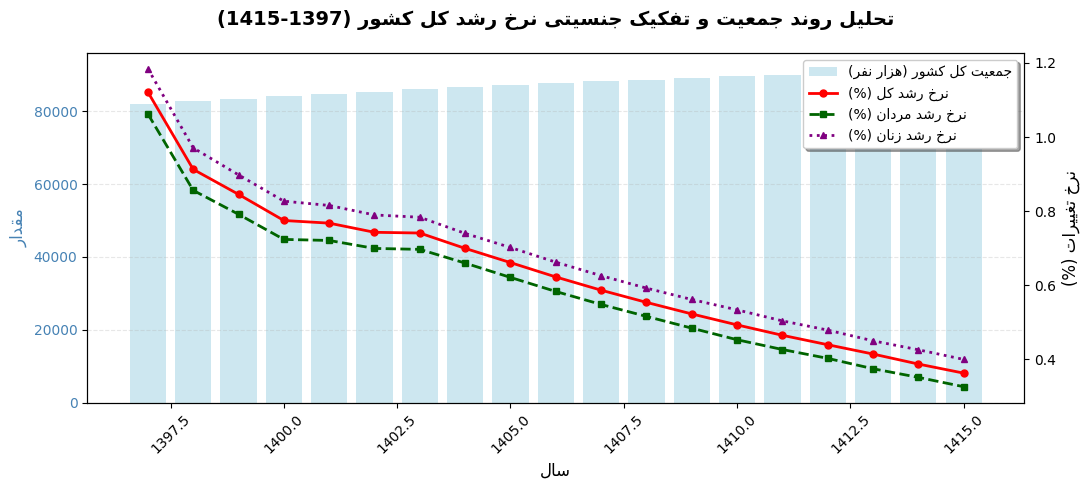

In [ ]:
# رسم نمودار ترکیبی جمعیت کل کشور و نرخ رشد با استفاده از تابع کمکی جامع
plot_combined_chart(
    df_growth=population_growth_df,
    df_raw=population_df,
    col_raw_total='کل_کشور',
    col_rate_total='نرخ_رشد_کل',
    col_rate_men='نرخ_رشد_مرد',
    col_rate_women='نرخ_رشد_زن',
    title_text='تحلیل روند جمعیت و تفکیک جنسیتی نرخ رشد کل کشور (1397-1415)',
    label_bar='جمعیت کل کشور (هزار نفر)',
    label_line_total='نرخ رشد کل (%)',
    label_line_men='نرخ رشد مردان (%)',
    label_line_women='نرخ رشد زنان (%)'
)



> «روند نرخ رشد جمعیت ایران از سال ۱۳۹۷ تا پیش‌بینی ۱۴۱۵، افت چشمگیری داشته است (از ۱.۱۲٪ به ۰.۳۶٪). این نشان‌دهنده ورود ایران به مرحله "پیری جمعیت" است. چالش‌های اصلی پیش‌رو شامل فشار بر نظام بازنشستگی، کمبود نیروی کار جوان و تغییر الگوی مصرف در اقتصاد کشور خواهد بود.»



#### روند نرخ رشد در مناطق شهری

In [ ]:
# محاسبه نرخ رشد مناطق شهری با استفاده از تابع کمکی ساختاریافته
urban_growth_df = calculate_growth_rates(
    df=population_df,
    col_total='شهر_کل',
    col_men='مرد_شهر',
    col_women='زن_شهر',
    out_total='نرخ_رشد_شهر',
    out_men='نرخ_رشد_مرد_شهر',
    out_women='نرخ_رشد_زن_شهر'
)
print("نمونه داده‌های نرخ رشد مناطق شهری:")
display(urban_growth_df.head())

نمونه داده‌های نرخ رشد مناطق شهری:


,سال,نرخ_رشد_شهر,نرخ_رشد_مرد_شهر,نرخ_رشد_زن_شهر
0,1397,1.670,1.612,1.730
1,1398,1.452,1.396,1.512
2,1399,1.375,1.319,1.428
3,1400,1.300,1.252,1.350
4,1401,1.220,1.171,1.269


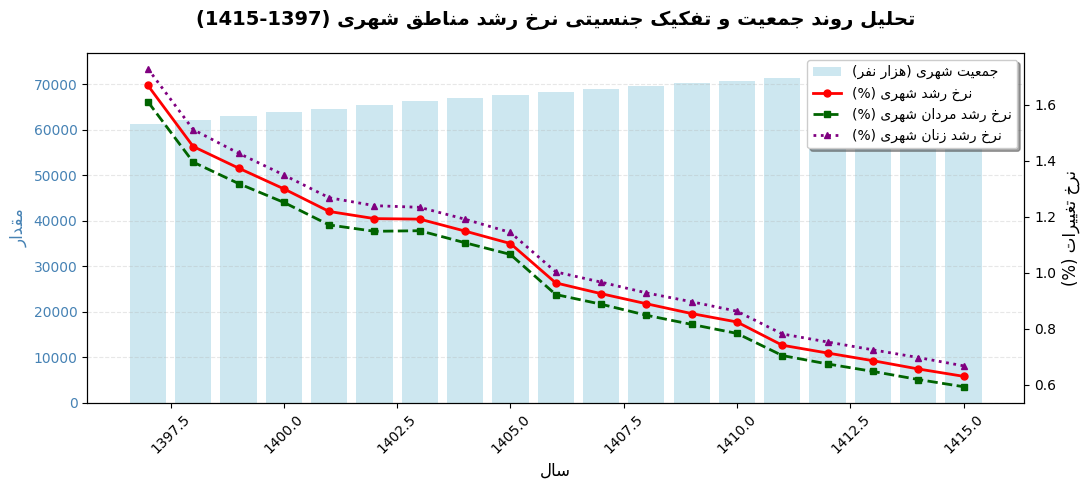

In [ ]:
# رسم نمودار ترکیبی جمعیت و نرخ رشد مناطق شهری به کمک تابع کمکی
plot_combined_chart(
    df_growth=urban_growth_df,
    df_raw=population_df,
    col_raw_total='شهر_کل',
    col_rate_total='نرخ_رشد_شهر',
    col_rate_men='نرخ_رشد_مرد_شهر',
    col_rate_women='نرخ_رشد_زن_شهر',
    title_text='تحلیل روند جمعیت و تفکیک جنسیتی نرخ رشد مناطق شهری (1397-1415)',
    label_bar='جمعیت شهری (هزار نفر)',
    label_line_total='نرخ رشد شهری (%)',
    label_line_men='نرخ رشد مردان شهری (%)',
    label_line_women='نرخ رشد زنان شهری (%)'
)

#### روند نرخ رشد در مناطق روستایی

In [ ]:
# محاسبه نرخ رشد مناطق روستایی با استفاده از تابع کمکی ساختاریافته
rural_growth_df = calculate_growth_rates(
    df=population_df,
    col_total='کل_روستا',
    col_men='مرد_روستا',
    col_women='زن_روستا',
    out_total='نرخ_رشد_روستا',
    out_men='نرخ_رشد_مرد_روستا',
    out_women='نرخ_رشد_زن_روستا'
)
print("نمونه داده‌های نرخ رشد مناطق روستایی:")
display(rural_growth_df.head())

نمونه داده‌های نرخ رشد مناطق روستایی:


,سال,نرخ_رشد_روستا,نرخ_رشد_مرد_روستا,نرخ_رشد_زن_روستا
0,1397,-0.467,-0.533,-0.400
1,1398,-0.692,-0.746,-0.637
2,1399,-0.761,-0.819,-0.701
3,1400,-0.855,-0.894,-0.805
4,1401,-0.664,-0.716,-0.621


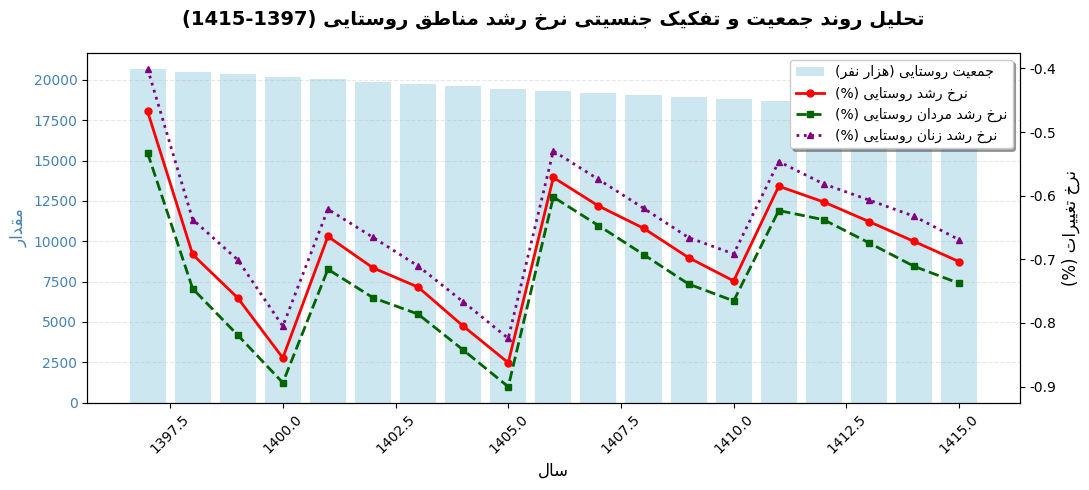

In [ ]:
# رسم نمودار ترکیبی جمعیت و نرخ رشد مناطق روستایی به کمک تابع کمکی
plot_combined_chart(
    df_growth=rural_growth_df,
    df_raw=population_df,
    col_raw_total='کل_روستا',
    col_rate_total='نرخ_رشد_روستا',
    col_rate_men='نرخ_رشد_مرد_روستا',
    col_rate_women='نرخ_رشد_زن_روستا',
    title_text='تحلیل روند جمعیت و تفکیک جنسیتی نرخ رشد مناطق روستایی (1397-1415)',
    label_bar='جمعیت روستایی (هزار نفر)',
    label_line_total='نرخ رشد روستایی (%)',
    label_line_men='نرخ رشد مردان روستایی (%)',
    label_line_women='نرخ رشد زنان روستایی (%)'
)

#### تفسیر روند جمعیت شهری و روستایی

<div dir="rtl" style="text-align: right; line-height: 1.8; font-family: Tahoma, Arial, sans-serif;">

**۱. تفسیر داده‌های مناطق روستایی (رشد منفی مداوم)**
* **آمار:** نرخ رشد جمعیت روستا از سال ۱۳۹۷ همواره منفی بوده است (بین -۰.۴٪ تا -۰.۸٪).
* **معنی:** روستاهای ایران در حال "خالی شدن" هستند. هر سال تعداد ساکنان روستا کمتر از سال قبل است.
* **علت اصلی (مهاجرت):** وقتی نرخ باروری (تولد منهای فوت) حتی اگر صفر باشد، اما مهاجرت جوانان به شهرها ادامه داشته باشد، رشد کل منفی می‌شود. داده‌ها نشان می‌دهد که خروج جمعیت از روستا سریع‌تر از ورود نوزاد یا ماندن افراد مسن است.
* **تفکیک جنسیتی جالب توجه:** در بسیاری از سال‌ها (مثل ۱۳۹۷، ۱۳۹۸)، نرخ کاهش جمعیت مردان روستایی (-0.533) بیشتر از زنان (-0.400) بوده است. این معمولاً نشانه‌ای از مهاجرت نیروی کار مرد برای یافتن شغل به شهرهاست، در حالی که زنان ممکن است به دلایل خانوادگی یا سنی در روستا بمانند.

**۲. تفسیر داده‌های مناطق شهری (رشد مثبت اما کاهشی)**
* **آمار:** نرخ رشد شهرها مثبت است (حدود ۱.۶٪ در ابتدا و کاهش به ۰.۶٪ در پیش‌بینی ۱۴۱۵).
* **معنی:** شهرها هنوز در حال جذب جمعیت هستند، اما سرعت این جذب در حال کم شدن است.
* **چرا کاهشی؟** دو دلیل دارد:
  1. **کاهش نرخ باروری ملی:** همانطور که در تحلیل قبلی دیدیم، تولدها در کل کشور کم شده است.
  2. **اشباع زیرساخت‌ها:** شهرهای بزرگ دیگر ظرفیت پذیرش جمعیت جدید را با همان سرعت گذشته ندارند.
* **نکته کلیدی:** نرخ رشد شهرها (مثلاً ۱.۶٪) بسیار بالاتر از نرخ رشد کل کشور (۱.۱٪) است. این یعنی شهرها موتور محرک رشد جمعیت ایران هستند و روستاها بار منفی آن را حمل می‌کنند.

</div>

### جدول ۲: متوسط تعداد افراد در خانوارهای کشور

In [ ]:
# ۱. استخراج جدول دوم به کمک تابع کمکی
title_2, body_2 = extract_table(df, *tables_info[1])

# ۲. تنظیم نام ستون سال و انتقال ستون‌ها (Transpose) جهت مرتب‌سازی
body_2.iloc[0, 0] = 'سال'
transposed_df = body_2.T
transposed_df.columns = transposed_df.iloc[0]
transposed_df = transposed_df.iloc[1:].reset_index(drop=True)

# ۳. عددی کردن کل مقادیر
transposed_df = transposed_df.apply(to_numeric_or_keep)

print(f"عنوان جدول ۲: {title_2}")
display(transposed_df)

عنوان جدول ۲: متوسط تعداد افراد در خانوارهای کشور


,سال,کل,شهری,روستایی
0,1335,4.800,4.700,4.800
1,1345,5.000,4.900,5.000
2,1355,5.000,4.800,5.200
3,1365,5.100,4.800,5.400
4,1370,5.200,4.900,5.600
5,1375,4.800,4.600,5.100
6,1385,4.000,3.900,4.400
7,1390,3.500,3.500,3.700
8,1395,3.300,3.300,3.400
9,1400,3.190,3.130,3.360


### جدول ۳: تعداد ولادت‌های ثبت‌شده برحسب جنس و مناطق

In [ ]:
# ۱. استخراج جدول سوم مربوط به ولادت‌ها
title_3, body_3 = extract_table(df, *tables_info[2])

# ۲. پاک‌سازی و نام‌گذاری مجدد با تابع clean_and_rename
cols_births = [
    'سال', 'کل_کشور', 'پسر_کشور', 'دختر_کشور',
    'شهر_کل', 'پسر_شهر', 'دختر_شهر',
    'روستا_کل', 'پسر_روستا', 'دختر_روستا'
]
births_df_clean = clean_and_rename(body_3, drop_rows=[0, 1], new_cols=cols_births)

# ۳. تبدیل مقادیر به نوع عددی
births_df_clean = births_df_clean.apply(pd.to_numeric, errors='coerce')

print(f"عنوان جدول ۳: {title_3}")
display(births_df_clean.head())

عنوان جدول ۳: تعداد ولادت‌های ثبت شده برحسب جنس و مناطق جغرافیایی


,سال,کل_کشور,پسر_کشور,دختر_کشور,شهر_کل,پسر_شهر,دختر_شهر,روستا_کل,پسر_روستا,دختر_روستا
0,1395.000,1528053,766142,741911,1176032,605523,570509,352021,180619,171402
1,1396.000,1487923,766140,721783,1143558,589111,554447,344355,177029,167336
2,1397.000,1366519,704067,662452,1047925,540372,507553,318594,163695,154899
3,1398.000,1196132,616483,579649,907694,467872,439822,288438,148611,139827
4,1399.000,1114115,575159,538956,837630,432411,405219,276485,142748,133737


In [ ]:
# ۴. محاسبه نرخ‌های رشد ولادت‌ها با استفاده از تابع کمکی
growth_births_clean = calculate_growth_rates(
    df=births_df_clean,
    col_total='کل_کشور',
    col_men='پسر_کشور',
    col_women='دختر_کشور',
    out_total='نرخ_تولد_کل',
    out_men='نرخ_تولد_پسر',
    out_women='نرخ_تولد_دختر'
)

print("نمونه داده‌های نرخ رشد ولادت‌ها:")
display(growth_births_clean.head())

نمونه داده‌های نرخ رشد ولادت‌ها:


,سال,نرخ_تولد_کل,نرخ_تولد_پسر,نرخ_تولد_دختر
0,1396.000,-2.626,-0.000,-2.713
1,1397.000,-8.159,-8.102,-8.220
2,1398.000,-12.469,-12.440,-12.499
3,1399.000,-6.857,-6.703,-7.020
4,1400.000,0.188,0.139,0.241


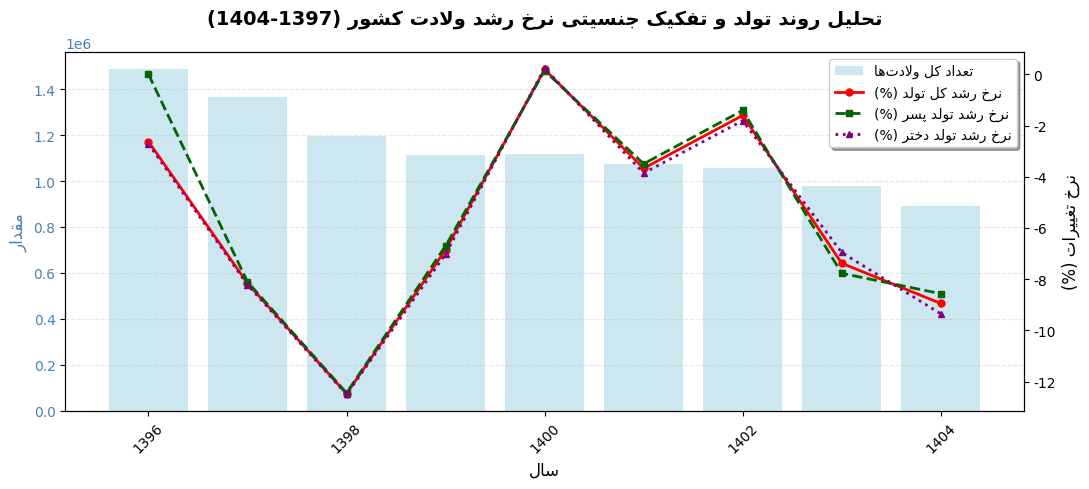

In [ ]:
# ۵. رسم نمودار ترکیبی ولادت‌ها برای بازه مشخص (۹ سال اول)
plot_combined_chart(
    df_growth=growth_births_clean[:-5],
    df_raw=births_df_clean[:-5],
    col_raw_total='کل_کشور',
    col_rate_total='نرخ_تولد_کل',
    col_rate_men='نرخ_تولد_پسر',
    col_rate_women='نرخ_تولد_دختر',
    title_text='تحلیل روند تولد و تفکیک جنسیتی نرخ رشد ولادت کشور (1397-1404)',
    label_bar='تعداد کل ولادت‌ها',
    label_line_total='نرخ رشد کل تولد (%)',
    label_line_men='نرخ رشد تولد پسر (%)',
    label_line_women='نرخ رشد تولد دختر (%)'
)

### جدول ۴: تعداد فوت‌های ثبت‌شده برحسب جنس و مناطق

#### کل کشور

In [ ]:
# ۱. استخراج جدول چهارم مربوط به فوت‌ها (ردیف ۵۲ تا ۶۹)
title_4, body_4 = extract_table(df, *tables_info[3])

# ۲. پاک‌سازی و نام‌گذاری مجدد با تابع clean_and_rename
cols_deaths = [
    'سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور',
    'شهر_کل', 'مرد_شهر', 'زن_شهر',
    'روستا_کل', 'مرد_روستا', 'زن_روستا'
]
deaths_df_clean = clean_and_rename(body_4, drop_rows=[0, 1], new_cols=cols_deaths)

# ۳. تبدیل مقادیر به نوع عددی و حذف داده‌های نامعتبر احتمالی
deaths_df_clean = deaths_df_clean.apply(pd.to_numeric, errors='coerce')

print(f"عنوان جدول ۴: {title_4}")
display(deaths_df_clean.head())

عنوان جدول ۴: تعداد فوت‌های ثبت شده برحسب جنس و مناطق جغرافیایی


,سال,کل_کشور,مرد_کشور,زن_کشور,شهر_کل,مرد_شهر,زن_شهر,روستا_کل,مرد_روستا,زن_روستا
0,1395.000,369751,161774,207884,274870,119038,155832,94788,42736,52052
1,1396.000,376731,210691,165987,278448,156692,121756,98230,53999,44231
2,1397.000,376953,211326,165557,279225,157799,121426,97658,53527,44131
3,1398.000,395319,223985,171258,295596,168767,126786,99647,55175,44472
4,1399.000,511881,289056,222776,387273,221032,166224,124559,68007,56552


In [ ]:
# ۴. محاسبه نرخ‌های تغییرات سالانه فوت‌ها با استفاده از تابع کمکی
growth_deaths_clean = calculate_growth_rates(
    df=deaths_df_clean,
    col_total='کل_کشور',
    col_men='مرد_کشور',
    col_women='زن_کشور',
    out_total='نرخ_فوت_کل',
    out_men='نرخ_فوت_مرد',
    out_women='نرخ_فوت_زن'
)

print("نمونه داده‌های نرخ رشد/تغییرات سالانه فوت‌ها:")
display(growth_deaths_clean.head())

نمونه داده‌های نرخ رشد/تغییرات سالانه فوت‌ها:


,سال,نرخ_فوت_کل,نرخ_فوت_مرد,نرخ_فوت_زن
0,1396.000,1.888,30.238,-20.154
1,1397.000,0.059,0.301,-0.259
2,1398.000,4.872,5.990,3.444
3,1399.000,29.486,29.051,30.082
4,1400.000,6.376,5.033,8.134


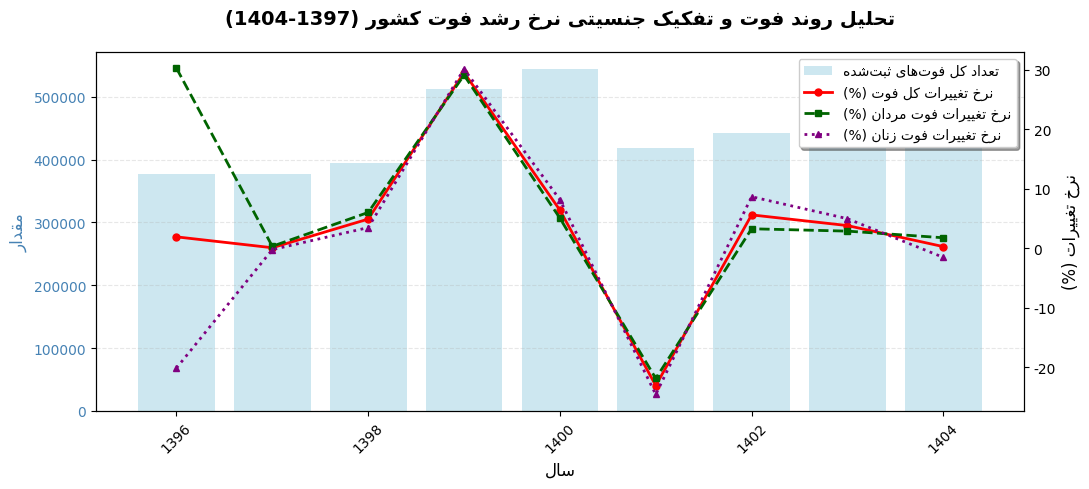

In [ ]:
# ۵. رسم نمودار ترکیبی فوت‌ها برای بازه زمانی مشخص (حذف ۵ سطر آخر جهت هم‌ترازی با سال‌های معتبر گذشته)
plot_combined_chart(
    df_growth=growth_deaths_clean[:-5],
    df_raw=deaths_df_clean[:-5],
    col_raw_total='کل_کشور',
    col_rate_total='نرخ_فوت_کل',
    col_rate_men='نرخ_فوت_مرد',
    col_rate_women='نرخ_فوت_زن',
    title_text='تحلیل روند فوت و تفکیک جنسیتی نرخ رشد فوت کشور (1397-1404)',
    label_bar='تعداد کل فوت‌های ثبت‌شده',
    label_line_total='نرخ تغییرات کل فوت (%)',
    label_line_men='نرخ تغییرات فوت مردان (%)',
    label_line_women='نرخ تغییرات فوت زنان (%)'
)

#### مناطق شهری

In [ ]:
# ۱. محاسبه نرخ تغییرات سالانه فوت در مناطق شهری با استفاده از تابع کمکی
urban_deaths_growth = calculate_growth_rates(
    df=deaths_df_clean,
    col_total='شهر_کل',
    col_men='مرد_شهر',
    col_women='زن_شهر',
    out_total='نرخ_فوت_شهر',
    out_men='نرخ_فوت_مرد_شهر',
    out_women='نرخ_فوت_زن_شهر'
)

print("نمونه داده‌های نرخ تغییرات فوت در مناطق شهری:")
display(urban_deaths_growth.head())

نمونه داده‌های نرخ تغییرات فوت در مناطق شهری:


,سال,نرخ_فوت_شهر,نرخ_فوت_مرد_شهر,نرخ_فوت_زن_شهر
0,1396.000,1.302,31.632,-21.867
1,1397.000,0.279,0.706,-0.271
2,1398.000,5.863,6.951,4.414
3,1399.000,31.014,30.969,31.106
4,1400.000,8.476,6.728,10.811


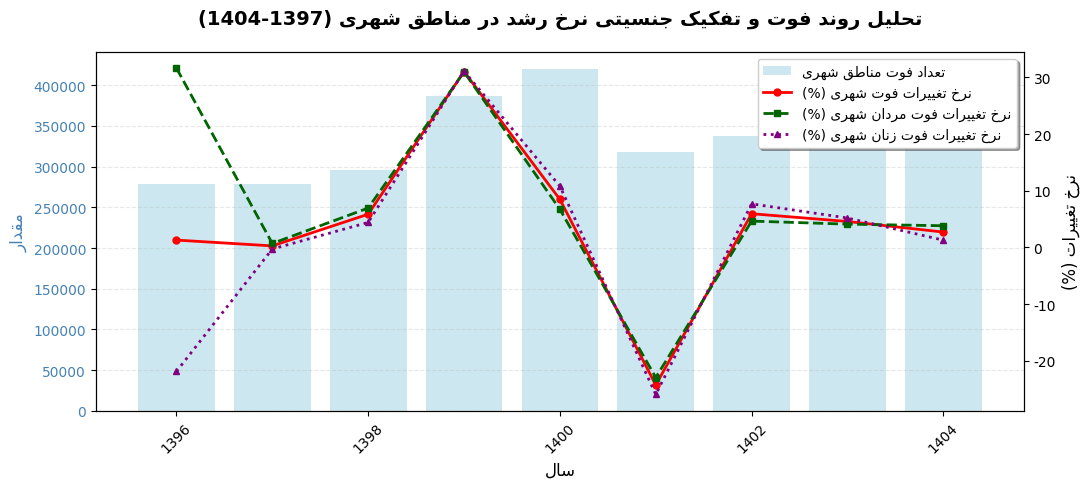

In [ ]:
# ۲. رسم نمودار ترکیبی فوت برای مناطق شهری
plot_combined_chart(
    df_growth=urban_deaths_growth[:-5],
    df_raw=deaths_df_clean[:-5],
    col_raw_total='شهر_کل',
    col_rate_total='نرخ_فوت_شهر',
    col_rate_men='نرخ_فوت_مرد_شهر',
    col_rate_women='نرخ_فوت_زن_شهر',
    title_text='تحلیل روند فوت و تفکیک جنسیتی نرخ رشد در مناطق شهری (1397-1404)',
    label_bar='تعداد فوت مناطق شهری',
    label_line_total='نرخ تغییرات فوت شهری (%)',
    label_line_men='نرخ تغییرات فوت مردان شهری (%)',
    label_line_women='نرخ تغییرات فوت زنان شهری (%)'
)

#### مناطق روستایی

In [ ]:
# ۱. محاسبه نرخ تغییرات سالانه فوت در مناطق روستایی با استفاده از تابع کمکی
rural_deaths_growth = calculate_growth_rates(
    df=deaths_df_clean,
    col_total='روستا_کل',
    col_men='مرد_روستا',
    col_women='زن_روستا',
    out_total='نرخ_فوت_روستا',
    out_men='نرخ_فوت_مرد_روستا',
    out_women='نرخ_فوت_زن_روستا'
)

print("نمونه داده‌های نرخ تغییرات فوت در مناطق روستایی:")
display(rural_deaths_growth.head())

نمونه داده‌های نرخ تغییرات فوت در مناطق روستایی:


,سال,نرخ_فوت_روستا,نرخ_فوت_مرد_روستا,نرخ_فوت_زن_روستا
0,1396.000,3.631,26.355,-15.025
1,1397.000,-0.582,-0.874,-0.226
2,1398.000,2.037,3.079,0.773
3,1399.000,25.000,23.257,27.163
4,1400.000,-0.126,-0.450,0.263


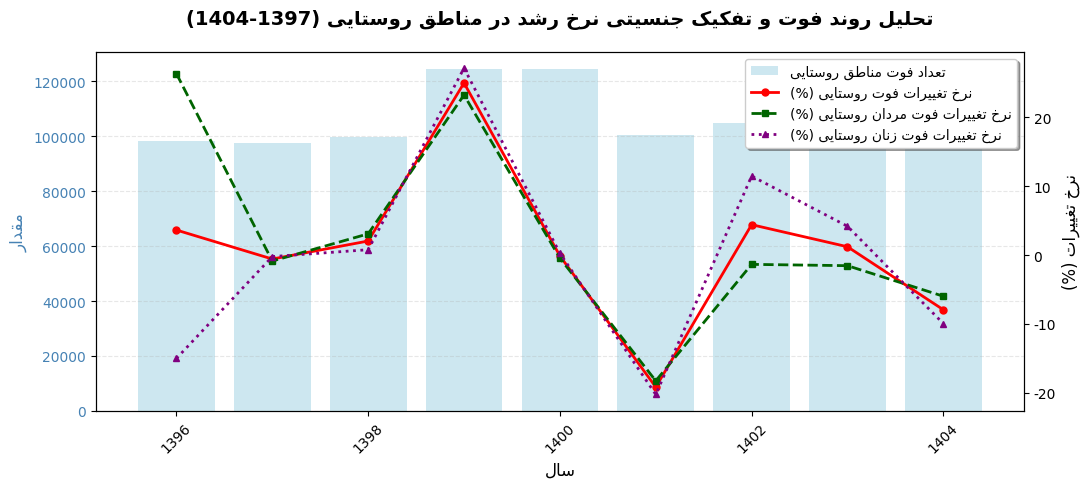

In [ ]:
# ۲. رسم نمودار ترکیبی فوت برای مناطق روستایی
plot_combined_chart(
    df_growth=rural_deaths_growth[:-5],
    df_raw=deaths_df_clean[:-5],
    col_raw_total='روستا_کل',
    col_rate_total='نرخ_فوت_روستا',
    col_rate_men='نرخ_فوت_مرد_روستا',
    col_rate_women='نرخ_فوت_زن_روستا',
    title_text='تحلیل روند فوت و تفکیک جنسیتی نرخ رشد در مناطق روستایی (1397-1404)',
    label_bar='تعداد فوت مناطق روستایی',
    label_line_total='نرخ تغییرات فوت روستایی (%)',
    label_line_men='نرخ تغییرات فوت مردان روستایی (%)',
    label_line_women='نرخ تغییرات فوت زنان روستایی (%)'
)

### مقایسه‌ی جامع ولادت و وفات (کل کشور، شهری و روستایی)

In [ ]:
# ۱. استخراج و آماده‌سازی داده‌های ولادت و فوت بر اساس سال‌های مشترک
# فرض بر این است که births_df_clean و deaths_df_clean از قبل آماده هستند.
# سال‌ها را به عنوان کلید اشتراک در نظر می‌گیریم:

comparison_df = pd.DataFrame(
    {
        'سال': births_df_clean['سال'],
        # ولادت‌ها
        'ولادت_کل': births_df_clean['کل_کشور'],
        'ولادت_شهری': births_df_clean['شهر_کل'],
        'ولادت_روستایی': births_df_clean['روستا_کل'],
        # وفات‌ها
        'وفات_کل': deaths_df_clean['کل_کشور'],
        'وفات_شهری': deaths_df_clean['شهر_کل'],
        'وفات_روستایی': deaths_df_clean['روستا_کل'],
    }
)

# حذف مقادیر خالی یا نا معتبر احتمالی و فیلتر کردن بازه معتبر (مثلا حذف ۵ سطر آخر پیش‌بینی یا ناقص اگر وجود داشته باشد)
comparison_df = comparison_df.dropna().reset_index(drop=True)

print('--- جدول مقایسه آمار ولادت و وفات (کل، شهری و روستایی) ---')
display(comparison_df)

--- جدول مقایسه آمار ولادت و وفات (کل، شهری و روستایی) ---


,سال,ولادت_کل,ولادت_شهری,ولادت_روستایی,وفات_کل,وفات_شهری,وفات_روستایی
0,1395.000,1528053,1176032,352021,369751,274870,94788
1,1396.000,1487923,1143558,344355,376731,278448,98230
2,1397.000,1366519,1047925,318594,376953,279225,97658
3,1398.000,1196132,907694,288438,395319,295596,99647
4,1399.000,1114115,837630,276485,511881,387273,124559
5,1400.000,1116212,844940,271272,544517,420099,124402
6,1401.000,1075231,813040,262191,418781,318237,100532
7,1402.000,1057964,800704,257260,442142,337175,104967
8,1403.000,979929,753496,226433,458858,352631,106227
9,1404.000,892278,693493,198785,459984,362207,97777


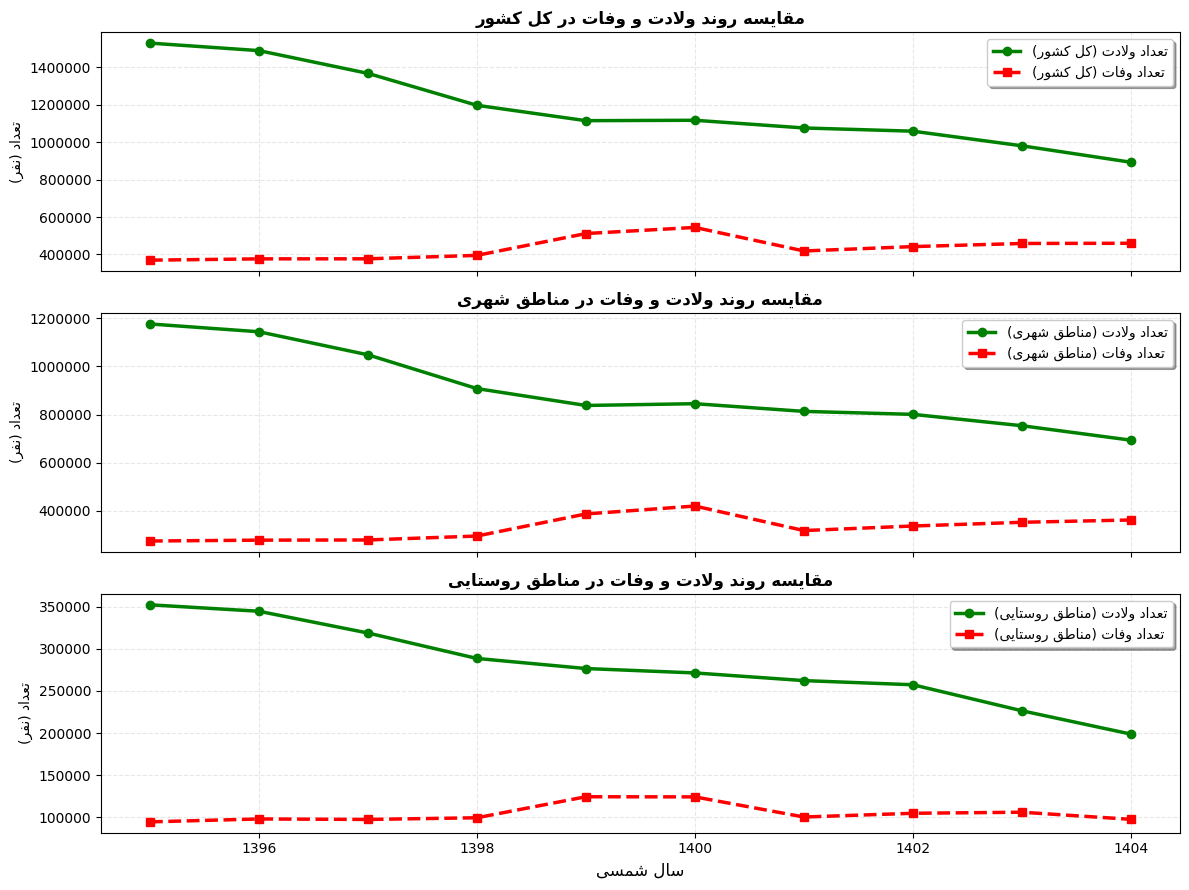

In [ ]:
# اجرای تابع رسم نمودار مقایسه‌ای
plot_birth_vs_death_comparison(comparison_df)

#### تحلیل مقایسه‌ای ولادت و وفات (شکاف حیاتی جمعیت)

<div dir="rtl" style="text-align: right; line-height: 1.8; font-family: Tahoma, Arial, sans-serif;">

1. **همگرایی نگران‌کننده خطوط ولادت و وفات:** بررسی نمودارهای مقایسه‌ای نشان می‌دهد که روند نزولی موالید در کنار شیب صعودی یا پایدار وفات‌ها، فاصله (شکاف) حیاتی بین تولد و مرگ را به شدت کاهش داده است. این پدیده به معنای افت چشمگیر نرخ رشد طبیعی جمعیت است.
2. **تفاوت ساختاری شهر و روستا:** در مناطق شهری، اگرچه حجم ولادت‌ها بالاتر است، اما سرعت رشد وفات‌ها به دلیل پدیده سالمندی و تجمع جمعیت مسن‌تر روند رو به رشدی دارد. در مناطق روستایی نیز با توجه به خروج جوانان و مهاجرت، نسبت سالخوردگان بالاتر رفته که این امر توازن حیاتی را بیشتر تحت تأثیر قرار می‌دهد.
3. **نتیجه‌گیری راهبردی:** استمرار این روند در سال‌های آتی به معنای صفر شدن یا حتی منفی شدن رشد طبیعی جمعیت کشور خواهد بود و سیاست‌گذاران باید برنامه‌ریزی فوری برای مواجهه با بحران سالمندی و افت نیروی کار جوان انجام دهند.

</div>

### جدول ۵: ازدواج و طلاق

In [ ]:
# استخراج و پاک‌سازی جدول ۵ (یک سطر هدر، ۳ ستون واقعی)
cols_marriage = ['سال', 'ازدواج', 'طلاق']
title_5, marriage_df = load_yearly_table(df, *tables_info[4], cols_marriage, header_rows=1)

print(f"عنوان: {title_5}")
display(marriage_df)

عنوان: ازدواج و طلاق ثبت شده در کشور (رویداد)


,سال,ازدواج,طلاق
0,1395,704716,181049
1,1396,612237,182913
2,1397,556315,179700
3,1398,536636,179217
4,1399,563567,188187
5,1400,573789,205284
6,1401,527871,208385
7,1402,484861,206477
8,1403,472590,197172
9,1404,431664,181327


In [ ]:
# ===== نرخ رشد و نمودار =====

marriage_growth_df = calculate_growth_rates_two(
    df=marriage_df,
    col_a='ازدواج', col_b='طلاق',
    out_a='نرخ_رشد_ازدواج', out_b='نرخ_رشد_طلاق'
)

print("نرخ رشد سالانه ازدواج و طلاق:")
display(marriage_growth_df)


نرخ رشد سالانه ازدواج و طلاق:


,سال,نرخ_رشد_ازدواج,نرخ_رشد_طلاق
0,1396,-13.123,1.030
1,1397,-9.134,-1.757
2,1398,-3.537,-0.269
3,1399,5.018,5.005
4,1400,1.814,9.085
5,1401,-8.003,1.511
6,1402,-8.148,-0.916
7,1403,-2.531,-4.507
8,1404,-8.660,-8.036


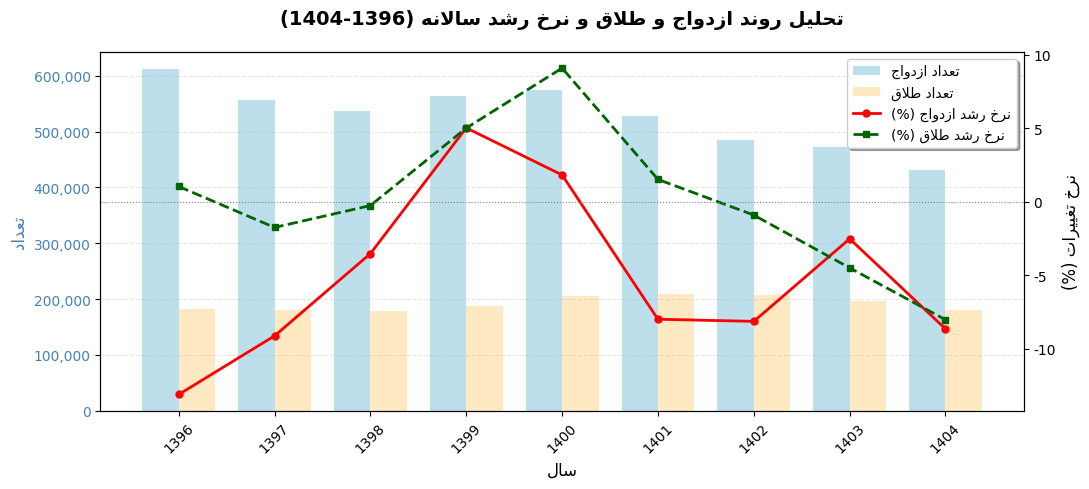

In [ ]:
plot_two_series_chart(
    df_growth=marriage_growth_df,
    df_raw=marriage_df,
    col_raw_a='ازدواج', col_raw_b='طلاق',
    col_rate_a='نرخ_رشد_ازدواج', col_rate_b='نرخ_رشد_طلاق',
    title_text='تحلیل روند ازدواج و طلاق و نرخ رشد سالانه (1396-1404)',
    label_bar_a='تعداد ازدواج', label_bar_b='تعداد طلاق',
    label_line_a='نرخ رشد ازدواج (%)', label_line_b='نرخ رشد طلاق (%)'
)

#### تفسیر روند ازدواج و طلاق (توضیحات احتمالی)

<div dir="rtl" style="text-align: right; line-height: 1.8; font-family: Tahoma, Arial, sans-serif;">

**کرونا و جابه‌جایی زمان ثبت:** در بهار ۱۳۹۹ محدودیت‌ها شدید بود. ممکن است مراسم‌ها و ثبت‌ها عقب افتاده باشند و بعداً در همان سال (یا در ۱۴۰۰) جبران شده باشند. اینکه ۱۴۰۰ هم کمی بالاتر است (۵۷۳٬۷۸۹) با این فرضیه می‌خواند.

**ثبت دیرهنگام:** ارقام «ثبت‌شده» هستند، نه رخداد واقعی. اگر دفاتر یا دادگاه‌ها مدتی تعطیل بوده باشند، پرونده‌های معوق بعداً ثبت می‌شوند. این برای طلاق هم صدق می‌کند، چون طلاق هم تقریباً با همان درصد رشد کرده است.

**سیاست‌های حمایتی:** مثلاً تسهیلات ازدواج یا تغییر قوانین. این را فقط با منبع بیرونی می‌شود تأیید کرد.

</div>

## ب) نیروی کار (جدول‌های ۶ تا ۱۲)

### جدول ۶: جمعیت ۱۵ ساله و بیشتر برحسب وضع فعالیت اقتصادی (هزار نفر)

In [ ]:
# استخراج و پاک‌سازی جدول ۶ (یک سطر هدر، ۵ ستون واقعی، سال‌های ۱۳۹۵ تا ۱۴۰۴)
cols_labor = ['سال', 'جمعیت_کل', 'جمعیت_فعال', 'جمعیت_شاغل', 'جمعیت_بیکار']
title_6, labor_df = load_yearly_table(df, *tables_info[5], cols_labor, header_rows=1, year_range=(1395, 1404))

print(f"عنوان: {title_6}")
display(labor_df)

عنوان: جمعیت 15 ساله و بیش‌تر برحسب وضع فعالیت اقتصادی (هزار نفر)


,سال,جمعیت_کل,جمعیت_فعال,جمعیت_شاغل,جمعیت_بیکار
0,1395,59528,25723,22525,3198
1,1396,59954,26504,23297,3207
2,1397,60632,26986,23731,3255
3,1398,61666,27168,24274,2894
4,1399,62376,25737,23263,2474
5,1400,63066,25822,23447,2375
6,1401,63794,26065,23716,2349
7,1402,64552,26638,24490,2148
8,1403,65338,26818,24788,2030
9,1404,66148,26837,24822,2014


In [ ]:
# ۵. کنترل سازگاری: فعال = شاغل + بیکار
diff = labor_df['جمعیت_فعال'] - labor_df['جمعیت_شاغل'] - labor_df['جمعیت_بیکار']
print("اختلاف فعال - (شاغل + بیکار):", diff.tolist())

اختلاف فعال - (شاغل + بیکار): [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]


In [ ]:
 #===== نرخ رشد سالانه =====

labor_growth_df = calculate_growth_rates_multi(
    df=labor_df,
    cols=['جمعیت_کل', 'جمعیت_فعال', 'جمعیت_شاغل', 'جمعیت_بیکار'],
    out_names=['رشد_جمعیت_۱۵+', 'رشد_فعال', 'رشد_شاغل', 'رشد_بیکار']
)
print("نرخ رشد سالانه (درصد):")
display(labor_growth_df)

نرخ رشد سالانه (درصد):


,سال,رشد_جمعیت_۱۵+,رشد_فعال,رشد_شاغل,رشد_بیکار
0,1396,0.716,3.036,3.427,0.281
1,1397,1.131,1.819,1.863,1.497
2,1398,1.705,0.674,2.288,-11.091
3,1399,1.151,-5.267,-4.165,-14.513
4,1400,1.106,0.330,0.791,-4.002
5,1401,1.154,0.941,1.147,-1.095
6,1402,1.188,2.198,3.264,-8.557
7,1403,1.218,0.676,1.217,-5.493
8,1404,1.240,0.071,0.137,-0.788


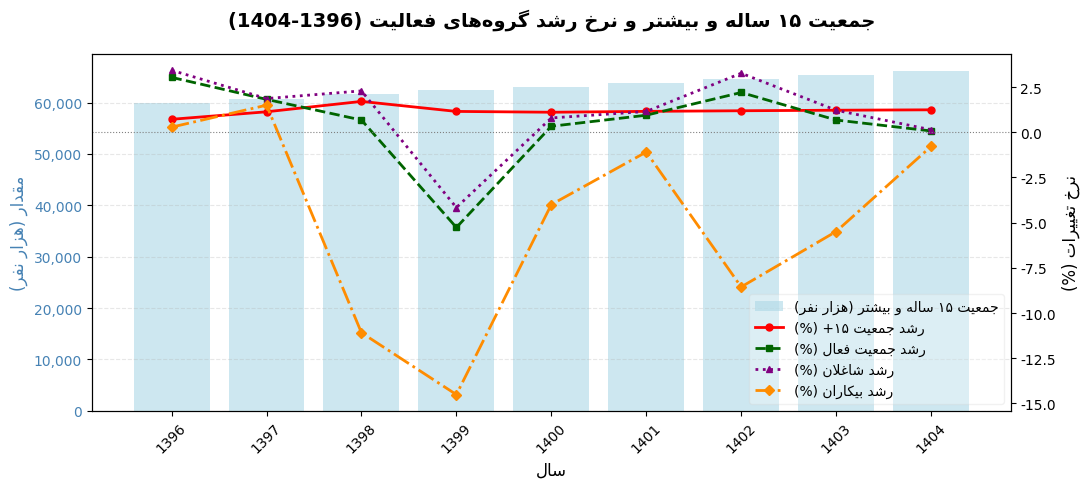

In [ ]:
plot_multi_growth_chart(
    df_growth=labor_growth_df,
    df_raw=labor_df,
    col_raw_total='جمعیت_کل',
    rate_cols=['رشد_جمعیت_۱۵+', 'رشد_فعال', 'رشد_شاغل', 'رشد_بیکار'],
    labels_lines=['رشد جمعیت ۱۵+ (%)', 'رشد جمعیت فعال (%)', 'رشد شاغلان (%)', 'رشد بیکاران (%)'],
    title_text='جمعیت ۱۵ ساله و بیشتر و نرخ رشد گروه‌های فعالیت (1396-1404)',
    label_bar='جمعیت ۱۵ ساله و بیشتر (هزار نفر)'
)


#### تفسیر نتایج

<div dir="rtl" style="text-align: right; line-height: 1.8; font-family: Tahoma, Arial, sans-serif;">

**نکات اصلی**

- **۱۳۹۹:** جمعیت فعال حدود ۱٫۴۳ میلیون نفر کم شده، در حالی که جمعیت ۱۵+ بیشتر شده است. جمعیت غیرفعال همان سال حدود ۲٫۱ میلیون نفر زیاد شده (۳۴٫۵ به ۳۶٫۶ میلیون).
- **افت بیکاری:** نرخ بیکاری از ۱۲٫۴٪ (۱۳۹۵) به ۷٫۵٪ (۱۴۰۴) رسیده، ولی نرخ مشارکت هم از ۴۴٫۵٪ (۱۳۹۷) به ۴۰٫۶٪ (۱۴۰۴) افتاده. بخشی از کاهش بیکاری یعنی افرادی که از جست‌وجوی کار بیرون رفته‌اند، نه اینکه شاغل شده باشند.
- **اشتغال:** از ۱۳۹۸ تا ۱۴۰۴ جمعیت ۱۵+ حدود ۷٫۳٪ بیشتر شده، ولی شاغلان فقط حدود ۲٫۳٪. نسبت اشتغال از ۳۹٫۴٪ به ۳۷٫۵٪ رسیده است.
- **۱۴۰۴:** رشد شاغلان تقریباً صفر است (۰٫۱٪).

**هشدارها و محدودیت‌ها**

- اختلاف ۱ نفری فعال و شاغل+بیکار در ۱۴۰۴ از گرد کردن اعداد است.
- افت ۱۳۹۹ با دوره‌ی کرونا هم‌زمان است، ولی این جدول علتش را نشان نمی‌دهد؛ بنابراین باید آن را «هم‌زمان با کرونا» توصیف کرد، نه «به دلیل کرونا».

</div>

### جدول ۷: نرخ مشارکت اقتصادی جمعیت ۱۵ ساله و بیشتر (درصد)

In [ ]:
# استخراج و پاک‌سازی جدول ۷ (دو سطر هدر، ۶ ستون واقعی، سال‌های ۱۳۹۵ تا ۱۴۰۴)
cols_part = ['سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور', 'نقاط_شهری', 'نقاط_روستایی']
title_7, part_df = load_yearly_table(df, *tables_info[6], cols_part, header_rows=2, year_range=(1395, 1404))

print(f"عنوان: {title_7}")
display(part_df)

عنوان: نرخ مشارکت اقتصادی جمعیت 15 ساله و بیش‌تر به تفکیک جنسیت، نقاط شهری و روستایی (درصد)


,سال,کل_کشور,مرد_کشور,زن_کشور,نقاط_شهری,نقاط_روستایی
0,1395,43.200,70.400,16.300,42.400,45.700
1,1396,44.200,70.900,17.400,43.200,47.400
2,1397,44.500,71.600,17.600,43.600,47.500
3,1398,44.100,71.100,17.000,43.000,47.300
4,1399,41.300,68.700,13.900,40.400,44.200
5,1400,40.900,68.700,13.300,40.300,43.200
6,1401,40.900,68.200,13.600,40.300,42.700
7,1402,41.300,68.400,14.200,40.800,42.900
8,1403,41.000,68.100,14.100,40.700,42.300
9,1404,40.600,67.900,13.400,40.200,41.900


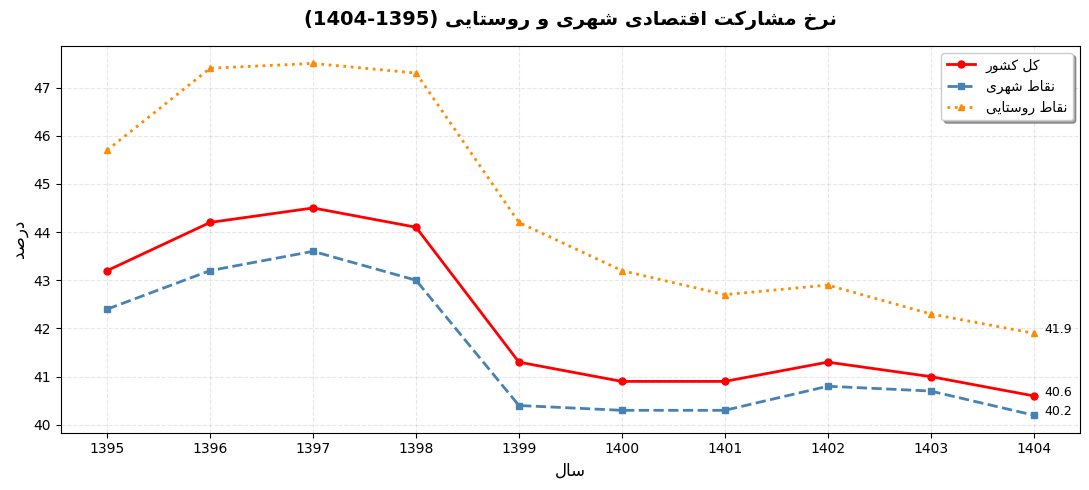

In [ ]:
plot_region_rates(part_df, 'نرخ مشارکت اقتصادی شهری و روستایی (1395-1404)')

### جدول ۸: نرخ بیکاری جمعیت ۱۵ ساله و بیشتر به تفکیک جنسیت، نقاط شهری و روستایی (درصد)

In [ ]:
# استخراج و پاک‌سازی جدول ۸ (ساختار مثل جدول ۷)
cols_unemp = ['سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور', 'نقاط_شهری', 'نقاط_روستایی']
title_8, unemp_df = load_yearly_table(df, *tables_info[7], cols_unemp, header_rows=2, year_range=(1395, 1404))

print(f"عنوان: {title_8}")
display(unemp_df)

عنوان: نرخ بیکاری جمعیت 15 ساله و بیش‌تر به تفکیک جنسیت، نقاط شهری و روستایی  (درصد)


,سال,کل_کشور,مرد_کشور,زن_کشور,نقاط_شهری,نقاط_روستایی
0,1395,12.400,10.500,20.700,13.700,8.900
1,1396,12.100,10.200,19.900,13.400,8.300
2,1397,12.100,10.400,18.900,13.500,8.000
3,1398,10.700,9.000,17.500,11.800,7.300
4,1399,9.600,8.400,15.600,10.400,7.200
5,1400,9.200,7.900,16.000,9.900,6.900
6,1401,9.000,7.700,15.800,9.700,6.700
7,1402,8.100,6.600,15.000,8.700,5.800
8,1403,7.600,6.200,14.300,8.100,5.700
9,1404,7.500,6.000,15.000,8.100,5.600


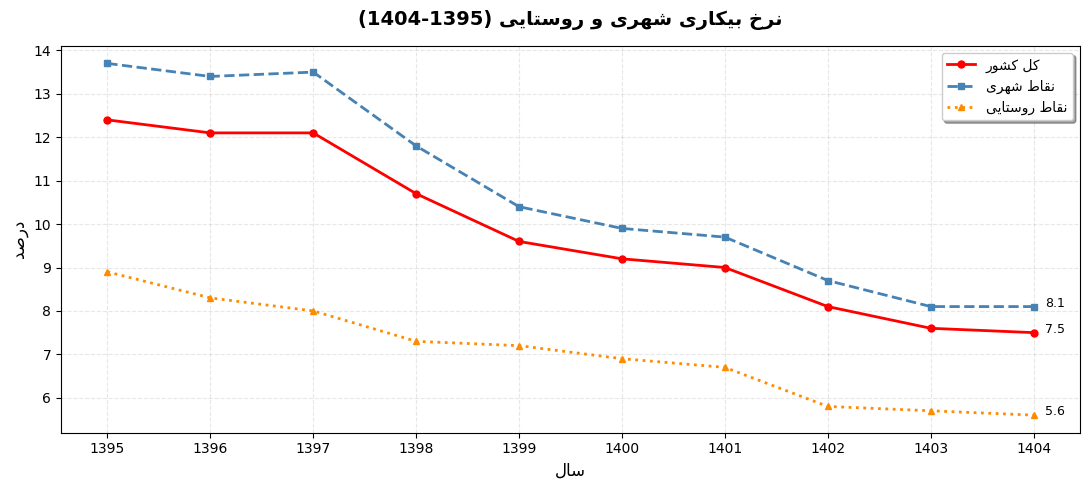

In [ ]:
plot_region_rates(unemp_df, 'نرخ بیکاری شهری و روستایی (1395-1404)')

### جدول ۹: نرخ بیکاری جمعیت ۱۵ تا ۲۴ ساله (درصد)

In [ ]:
# استخراج و پاک‌سازی جدول ۹ (ساختار مثل جدول ۷)
cols_youth = ['سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور', 'نقاط_شهری', 'نقاط_روستایی']
title_9, youth_df = load_yearly_table(df, *tables_info[8], cols_youth, header_rows=2, year_range=(1395, 1404))

print(f"عنوان: {title_9}")
display(youth_df)

عنوان: نرخ بیکاری جمعیت 24-15 ساله به تفکیک جنسیت، نقاط شهری و روستایی  (درصد)


,سال,کل_کشور,مرد_کشور,زن_کشور,نقاط_شهری,نقاط_روستایی
0,1395,29.200,25.400,44.200,32.300,22.500
1,1396,28.200,24.200,43.300,31.600,20.500
2,1397,27.700,24.300,40.100,31.600,18.900
3,1398,26.000,22.700,38.800,29.100,19.100
4,1399,23.700,21.200,36.000,26.000,18.400
5,1400,23.700,20.900,37.000,26.100,17.600
6,1401,22.600,19.900,36.100,24.500,17.700
7,1402,21.200,18.600,31.800,22.700,17.100
8,1403,20.100,17.700,30.400,21.100,17.400
9,1404,20.300,17.500,33.200,21.200,17.900


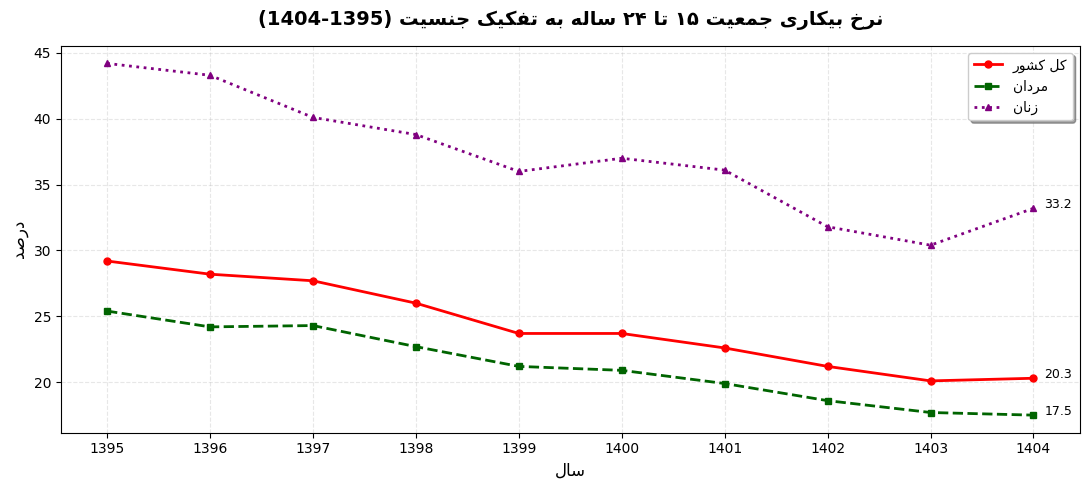

In [ ]:
plot_rate_lines(
    youth_df, ['کل_کشور', 'مرد_کشور', 'زن_کشور'],
    ['کل کشور', 'مردان', 'زنان'],
    [('red', 'o', '-'), ('darkgreen', 's', '--'), ('purple', '^', ':')],
    'نرخ بیکاری جمعیت ۱۵ تا ۲۴ ساله به تفکیک جنسیت (1395-1404)'
)

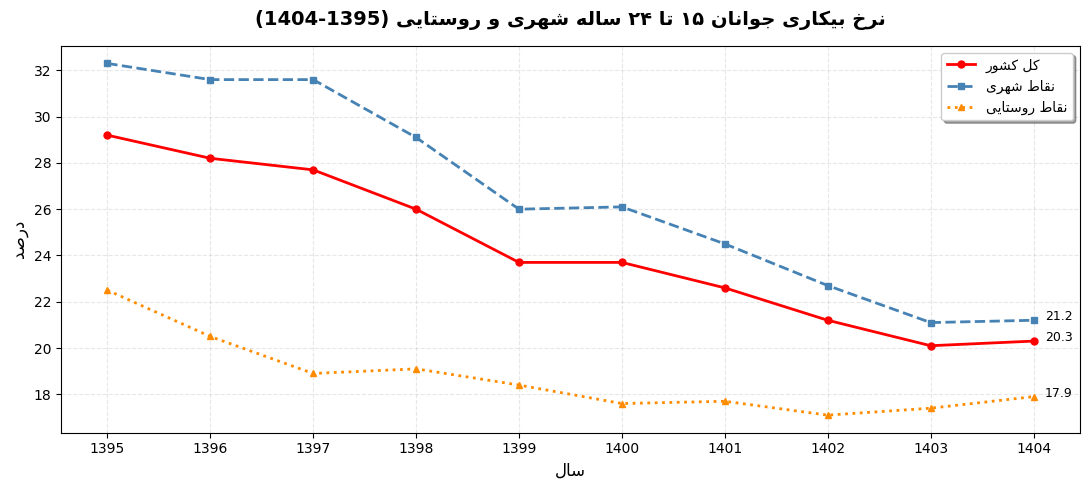

In [ ]:
plot_region_rates(youth_df, 'نرخ بیکاری جوانان ۱۵ تا ۲۴ ساله شهری و روستایی (1395-1404)')

### جدول ۱۰: نرخ بیکاری جمعیت ۱۸ تا ۳۵ ساله (درصد)

In [ ]:
# استخراج و پاک‌سازی جدول ۱۰ (ساختار مثل جدول ۷)
cols_18_35 = ['سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور', 'نقاط_شهری', 'نقاط_روستایی']
title_10, y3_df = load_yearly_table(df, *tables_info[9], cols_18_35, header_rows=2, year_range=(1395, 1404))

print(f"عنوان: {title_10}")
display(y3_df)

عنوان: نرخ بیکاری جمعیت 35-18 ساله به تفکیک جنسیت، نقاط شهری و روستایی  (درصد)


,سال,کل_کشور,مرد_کشور,زن_کشور,نقاط_شهری,نقاط_روستایی
0,1395,26.800,23.300,41.200,31.400,18.400
1,1396,19.700,15.900,33.000,21.200,14.700
2,1397,19.600,16.300,31.600,21.500,13.800
3,1398,17.900,14.800,29.700,19.600,12.900
4,1399,16.700,14.100,27.900,17.900,12.900
5,1400,16.500,13.800,28.300,17.600,12.700
6,1401,16.300,13.500,27.800,17.300,12.800
7,1402,15.200,12.300,26.000,16.100,11.900
8,1403,14.700,12.000,24.900,15.500,11.900
9,1404,15.000,12.100,26.000,15.700,12.300


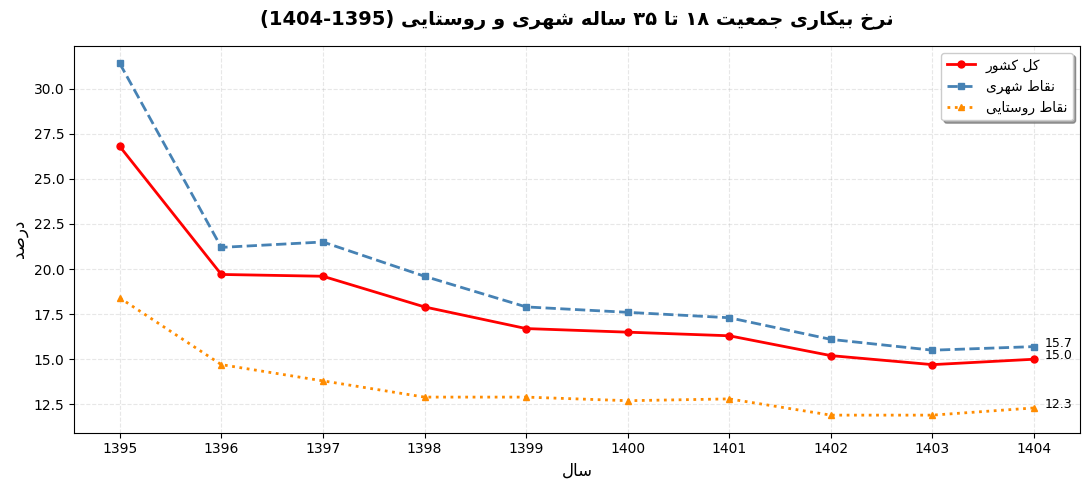

In [ ]:
plot_region_rates(y3_df, 'نرخ بیکاری جمعیت ۱۸ تا ۳۵ ساله شهری و روستایی (1395-1404)')

### جدول ۱۱: نسبت اشتغال به تفکیک جنسیت، نقاط شهری و روستایی (درصد)

In [ ]:
# استخراج و پاک‌سازی جدول ۱۱ (ساختار مثل جدول ۷)
cols_emp = ['سال', 'کل_کشور', 'مرد_کشور', 'زن_کشور', 'نقاط_شهری', 'نقاط_روستایی']
title_11, emp_df = load_yearly_table(df, *tables_info[10], cols_emp, header_rows=2, year_range=(1395, 1404))

print(f"عنوان: {title_11}")
display(emp_df)

عنوان: نسبت اشتغال به تفکیک جنسیت، نقاط شهری و روستایی  (درصد)


,سال,کل_کشور,مرد_کشور,زن_کشور,نقاط_شهری,نقاط_روستایی
0,1395,37.800,63.000,12.900,36.600,41.600
1,1396,38.900,63.700,14.000,37.400,43.400
2,1397,39.100,64.200,14.200,37.700,43.700
3,1398,39.400,64.700,14.000,38.000,43.800
4,1399,37.300,62.900,11.700,36.200,41.000
5,1400,37.200,63.300,11.100,36.300,40.200
6,1401,37.200,63.000,11.400,36.400,39.900
7,1402,37.900,63.900,12.100,37.200,40.400
8,1403,37.900,63.900,12.100,37.400,39.900
9,1404,37.500,63.800,11.400,37.000,39.600


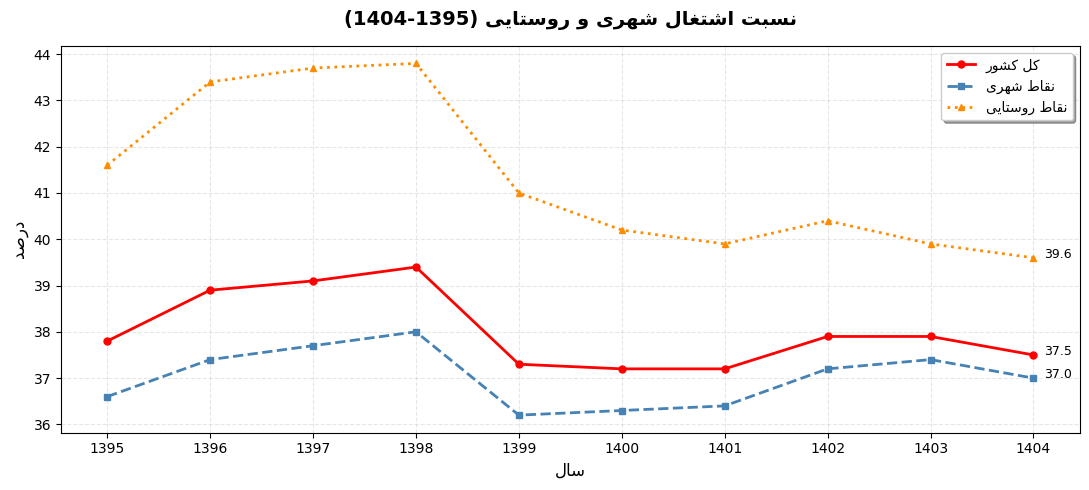

In [ ]:
plot_region_rates(emp_df, 'نسبت اشتغال شهری و روستایی (1395-1404)')

### جدول ۱۲: سهم شاغلان ۱۵ ساله و بیشتر در بخش‌های عمده‌ی اقتصادی (درصد)

In [ ]:
# استخراج و پاک‌سازی جدول ۱۲ (یک سطر هدر، ۴ ستون واقعی)
cols_sector = ['سال', 'کشاورزی', 'صنعت', 'خدمات']
title_12, sector_df = load_yearly_table(df, *tables_info[11], cols_sector, header_rows=1, year_range=(1395, 1404))

print(f"عنوان: {title_12}")
display(sector_df)

عنوان: سهم شاغلان 15 ساله و بیش‌تر در بخش‌های عمده اقتصادی از کل اشتغال (درصد)


,سال,کشاورزی,صنعت,خدمات
0,1395,17.900,31.900,50.200
1,1396,17.500,32.000,50.500
2,1397,17.700,32.000,50.300
3,1398,17.700,32.000,50.300
4,1399,17.400,33.300,49.300
5,1400,16.300,33.800,49.800
6,1401,14.800,33.600,51.600
7,1402,14.400,33.700,51.900
8,1403,13.900,33.300,52.700
9,1404,13.900,32.800,53.200


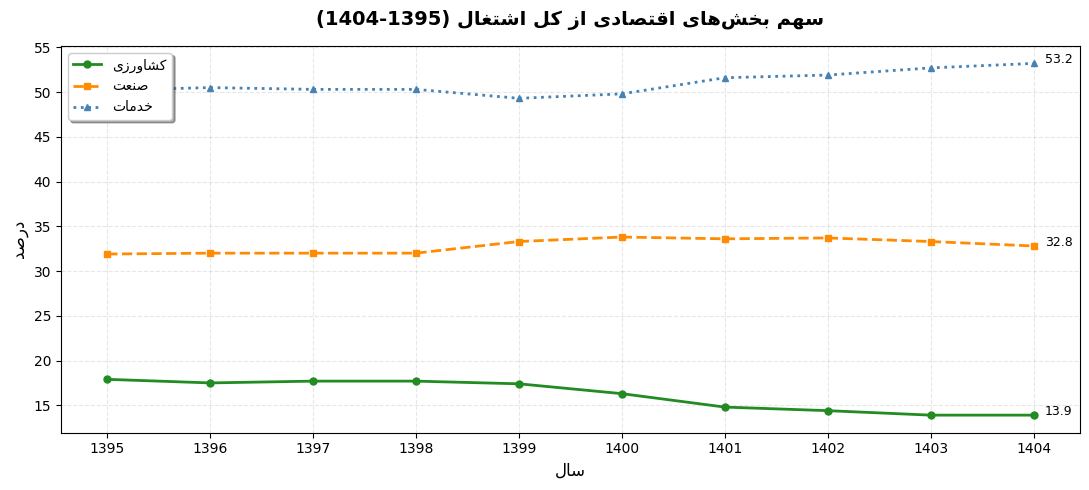

In [ ]:
# ===== نمودار روند سهم بخش‌ها =====

plot_rate_lines(
    sector_df, ['کشاورزی', 'صنعت', 'خدمات'],
    ['کشاورزی', 'صنعت', 'خدمات'],
    [('forestgreen', 'o', '-'), ('darkorange', 's', '--'), ('steelblue', '^', ':')],
    'سهم بخش‌های اقتصادی از کل اشتغال (1395-1404)'
)

## ج) آموزش (جدول‌های ۱۳ تا ۱۵)

### جدول ۱۳: تعداد دانش‌آموزان به تفکیک جنسیت

In [ ]:
# ۱. استخراج جدول و تغییر نام ستون اول به «سال تحصیلی»
title_13, body_13 = extract_table(df, *tables_info[12])
body_13 = body_13.iloc[:, :4]
students_df = clean_and_rename(body_13, drop_rows=[0], new_cols=['سال تحصیلی', 'کل', 'پسر', 'دختر'])

# ۲. فقط ردیف‌هایی که بازه‌ی سال دارند (دارای «-»)؛ هفت ردیف دوره‌های تحصیلی حذف می‌شوند
students_df = students_df[students_df['سال تحصیلی'].astype(str).str.contains('-')].copy()

# ۳. جدا کردن بازه با «-» به دو ستون (مثل Split Column در Power Query)
students_df[['سال شروع', 'سال پایان']] = students_df['سال تحصیلی'].str.split('-', expand=True)
students_df['سال شروع'] = students_df['سال شروع'].astype(int)
students_df['سال پایان'] = students_df['سال پایان'].astype(int)

# ۴. عددی کردن ستون‌های تعداد
students_df[['کل', 'پسر', 'دختر']] = students_df[['کل', 'پسر', 'دختر']].apply(pd.to_numeric)

# ۵. فقط سال‌های ۱۳۹۰ تا ۱۴۰۳ (بازه‌های یک‌ساله)
students_df = students_df[(students_df['سال شروع'] >= 1390) & (students_df['سال شروع'] <= 1403)]
students_df = students_df.reset_index(drop=True)

# ۶. حذف ستون‌های کمکی (فقط «سال شروع» لازم است)
students_df = students_df.drop(columns=['سال پایان', 'سال تحصیلی'])

print(f"عنوان: {title_13}")
display(students_df)

عنوان: تعداد دانش آموزان به تفکیک جنسیت


,کل,پسر,دختر,سال شروع
0,13351254,6932408,6418846,1390
1,13226473,6861311,6365162,1391
2,13406458,6964461,6441997,1392
3,13615311,7064602,6550709,1393
4,13861901,7174229,6687672,1394
5,14220342,7349326,6871016,1395
6,14700309,7599675,7100634,1396
7,15462046,8001045,7461001,1397
8,15774075,8137984,7636091,1398
9,15666587,8073596,7592991,1399


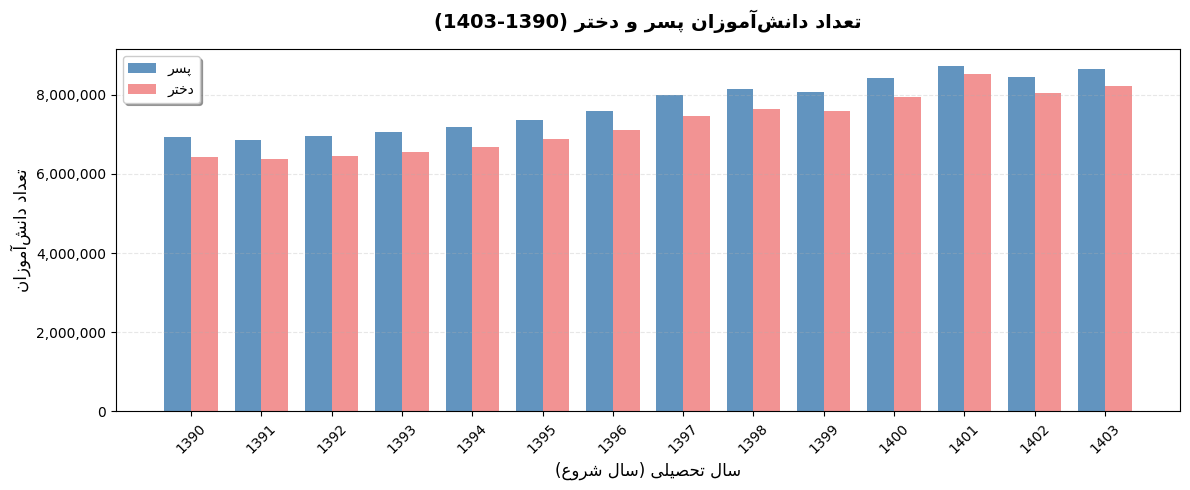

In [ ]:
# ===== نمودار میله‌ای: تعداد دانش‌آموزان پسر و دختر =====

x = np.arange(len(students_df))
w = 0.38

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - w/2, students_df['پسر'], w, color='steelblue', alpha=0.85, label=fix_persian_text('پسر'))
ax.bar(x + w/2, students_df['دختر'], w, color='lightcoral', alpha=0.85, label=fix_persian_text('دختر'))

ax.set_xticks(x)
ax.set_xticklabels(students_df['سال شروع'], rotation=45)
ax.set_xlabel(fix_persian_text('سال تحصیلی (سال شروع)'), fontsize=12)
ax.set_ylabel(fix_persian_text('تعداد دانش‌آموزان'), fontsize=12)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title(fix_persian_text('تعداد دانش‌آموزان پسر و دختر (1390-1403)'), fontsize=14, fontweight='bold', pad=15)
ax.legend(frameon=True, shadow=True)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### جدول ۱۴: تعداد دانشجویان دوره‌های مختلف تحصیلی موسسات آموزش عالی به تفکیک گروه عمده رشته تحصیلی و جنسیت

In [ ]:
# ===== جدول ۱۴: دانشجویان =====

title_14, students_uni_df, fields_uni_df, label_14 = parse_higher_edu_table(df, *tables_info[13])

print(f"عنوان: {title_14}")
display(students_uni_df)
display(fields_uni_df)

عنوان: تعداد دانشجویان دوره‌های مختلف تحصیلی موسسات آموزش عالی به تفکیک گروه عمده رشته تحصیلی و جنسیت


,سال,کل,مرد,زن
0,1394,4348383,2345824,2002559
1,1395,4073827,2202231,1871596
2,1396,3616114,1930954,1685160
3,1397,3373388,1768931,1604457
4,1398,3182989,1638746,1544243
5,1399,3070748,1556792,1513956
6,1400,3342220,1700794,1641426
7,1401,3249601,1618505,1631096
8,1402,3351877,1651073,1700804
9,1403,3503179,1684930,1818249


,گروه,کل,مرد,زن
0,پزشکی,316615,130314,186301
1,علوم انسانی,1836773,775928,1060845
2,علوم پایه,215535,67519,148016
3,فنی و مهندسی,774434,582615,191819
4,کشاورزی و دامپزشکی,110628,52658,57970
5,هنر,249194,75896,173298


In [ ]:
# --- نرخ رشد سالانه ---
uni_growth_df = calculate_growth_rates(
    students_uni_df, col_total='کل', col_men='مرد', col_women='زن',
    out_total='نرخ_رشد_کل', out_men='نرخ_رشد_مرد', out_women='نرخ_رشد_زن'
)
display(uni_growth_df)

,سال,نرخ_رشد_کل,نرخ_رشد_مرد,نرخ_رشد_زن
0,1395,-6.314,-6.121,-6.540
1,1396,-11.235,-12.318,-9.961
2,1397,-6.712,-8.391,-4.789
3,1398,-5.644,-7.360,-3.753
4,1399,-3.526,-5.001,-1.961
5,1400,8.841,9.250,8.420
6,1401,-2.771,-4.838,-0.629
7,1402,3.147,2.012,4.274
8,1403,4.514,2.051,6.905


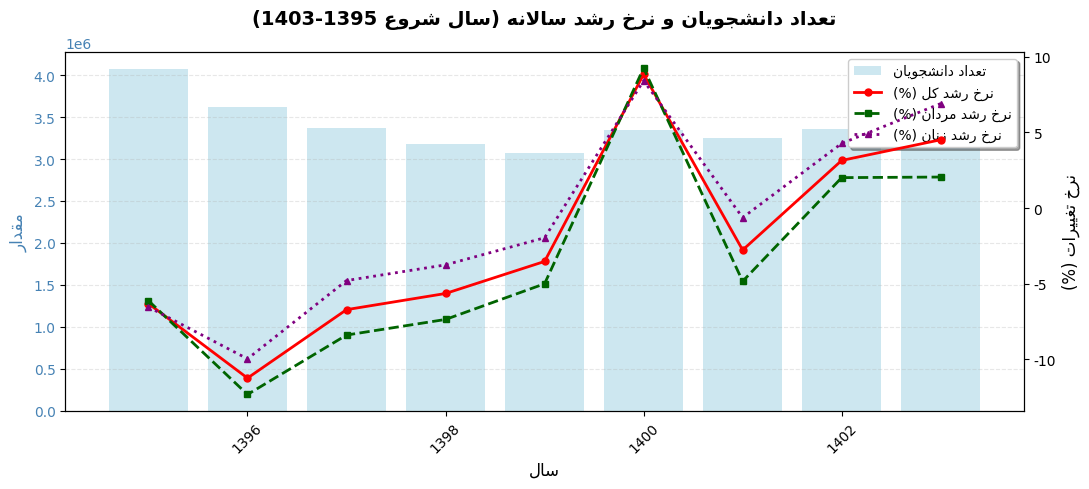

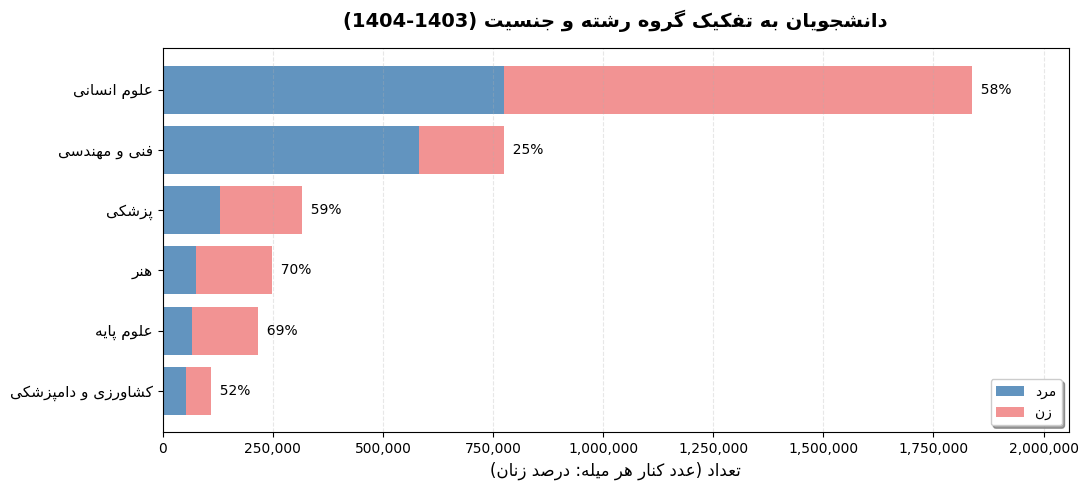

In [ ]:
plot_combined_chart(
    df_growth=uni_growth_df, df_raw=students_uni_df, col_raw_total='کل',
    col_rate_total='نرخ_رشد_کل', col_rate_men='نرخ_رشد_مرد', col_rate_women='نرخ_رشد_زن',
    title_text='تعداد دانشجویان و نرخ رشد سالانه (سال شروع 1395-1403)',
    label_bar='تعداد دانشجویان',
    label_line_total='نرخ رشد کل (%)', label_line_men='نرخ رشد مردان (%)', label_line_women='نرخ رشد زنان (%)'
)

# --- تفکیک گروه رشته در آخرین سال جدول ---
plot_field_breakdown(fields_uni_df, label_14, 'دانشجویان به تفکیک گروه رشته و جنسیت')

### جدول ۱۵: تعداد دانش‌آموختگان دوره‌های مختلف تحصیلی موسسات آموزش عالی به تفکیک گروه عمده رشته تحصیلی و جنسیت

In [ ]:
# ===== جدول ۱۵: دانش‌آموختگان =====

title_15, grads_df, fields_grad_df, label_15 = parse_higher_edu_table(df, *tables_info[14])

print(f"عنوان: {title_15}")
display(grads_df)
display(fields_grad_df)

عنوان: تعداد دانش آموختگان دوره‌های مختلف تحصیلی موسسات آموزش عالی به تفکیک گروه عمده رشته تحصیلی و جنسیت


,سال,کل,مرد,زن
0,1394,798736,466223,332513
1,1395,779646,457164,322482
2,1396,695055,393815,301240
3,1397,640262,366054,274208
4,1398,675724,378321,297403
5,1399,516416,275388,241028
6,1400,526520,272508,254012
7,1401,496172,254563,241609
8,1402,455335,233156,222179


,گروه,کل,مرد,زن
0,پزشکی,38450,15530,22920
1,علوم انسانی,241740,113497,128243
2,علوم پایه,24505,8519,15986
3,فنی و مهندسی,104401,79745,24656
4,کشاورزی و دامپزشکی,13696,6979,6717
5,هنر,32543,8886,23657


In [ ]:
# --- نرخ رشد سالانه ---
grads_growth_df = calculate_growth_rates(
    grads_df, col_total='کل', col_men='مرد', col_women='زن',
    out_total='نرخ_رشد_کل', out_men='نرخ_رشد_مرد', out_women='نرخ_رشد_زن'
)
display(grads_growth_df)

,سال,نرخ_رشد_کل,نرخ_رشد_مرد,نرخ_رشد_زن
0,1395,-2.390,-1.943,-3.017
1,1396,-10.850,-13.857,-6.587
2,1397,-7.883,-7.049,-8.974
3,1398,5.539,3.351,8.459
4,1399,-23.576,-27.208,-18.956
5,1400,1.957,-1.046,5.387
6,1401,-5.764,-6.585,-4.883
7,1402,-8.230,-8.409,-8.042


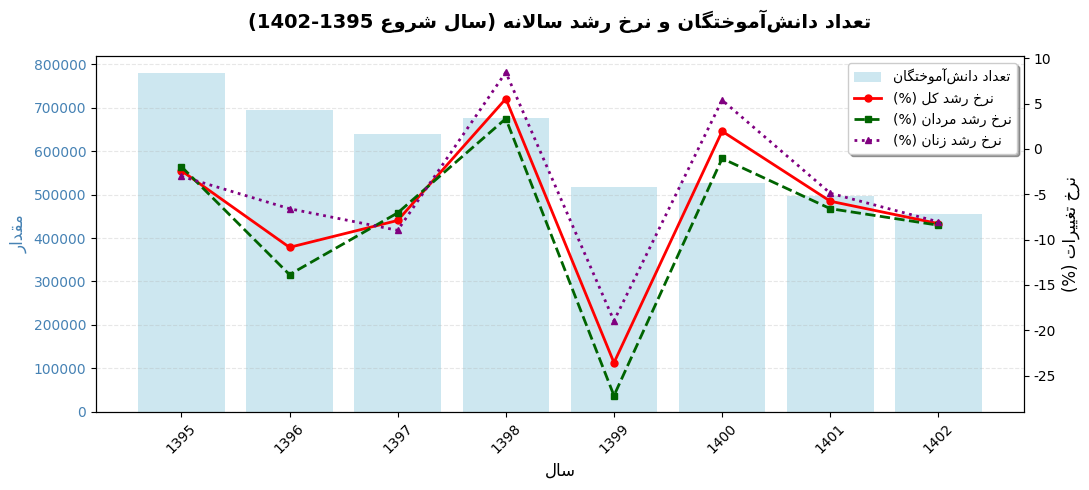

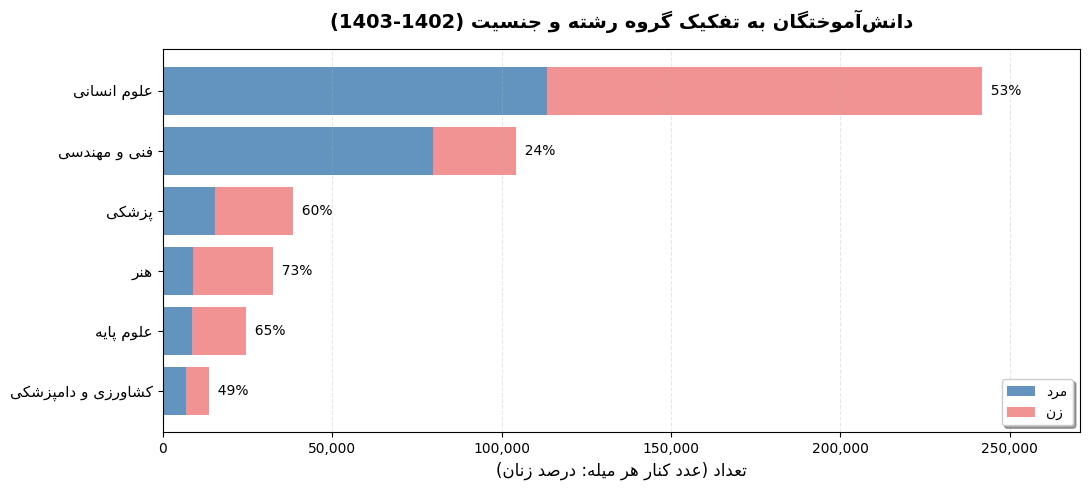

In [ ]:
plot_combined_chart(
    df_growth=grads_growth_df, df_raw=grads_df, col_raw_total='کل',
    col_rate_total='نرخ_رشد_کل', col_rate_men='نرخ_رشد_مرد', col_rate_women='نرخ_رشد_زن',
    title_text='تعداد دانش‌آموختگان و نرخ رشد سالانه (سال شروع 1395-1402)',
    label_bar='تعداد دانش‌آموختگان',
    label_line_total='نرخ رشد کل (%)', label_line_men='نرخ رشد مردان (%)', label_line_women='نرخ رشد زنان (%)'
)

# --- تفکیک گروه رشته در آخرین سال جدول ---
plot_field_breakdown(fields_grad_df, label_15, 'دانش‌آموختگان به تفکیک گروه رشته و جنسیت')

### مقایسه‌ی دانشجویان (جدول ۱۴) و دانش‌آموختگان (جدول ۱۵)

In [ ]:
# ۱. ترکیب دو جدول بر اساس «سال» (فقط سال‌های مشترک: ۱۳۹۴ تا ۱۴۰۲)
compare_df = students_uni_df.merge(grads_df, on='سال', suffixes=('_دانشجو', '_فارغ'))

# ۲. نسبت دانش‌آموختگان به دانشجویان (درصد)
compare_df['نسبت_کل'] = compare_df['کل_فارغ'] / compare_df['کل_دانشجو'] * 100
compare_df['نسبت_مرد'] = compare_df['مرد_فارغ'] / compare_df['مرد_دانشجو'] * 100
compare_df['نسبت_زن'] = compare_df['زن_فارغ'] / compare_df['زن_دانشجو'] * 100

display(compare_df[['سال', 'کل_دانشجو', 'کل_فارغ', 'نسبت_کل', 'نسبت_مرد', 'نسبت_زن']])


,سال,کل_دانشجو,کل_فارغ,نسبت_کل,نسبت_مرد,نسبت_زن
0,1394,4348383,798736,18.369,19.875,16.604
1,1395,4073827,779646,19.138,20.759,17.230
2,1396,3616114,695055,19.221,20.395,17.876
3,1397,3373388,640262,18.980,20.694,17.090
4,1398,3182989,675724,21.229,23.086,19.259
5,1399,3070748,516416,16.817,17.689,15.920
6,1400,3342220,526520,15.754,16.022,15.475
7,1401,3249601,496172,15.269,15.728,14.813
8,1402,3351877,455335,13.584,14.121,13.063


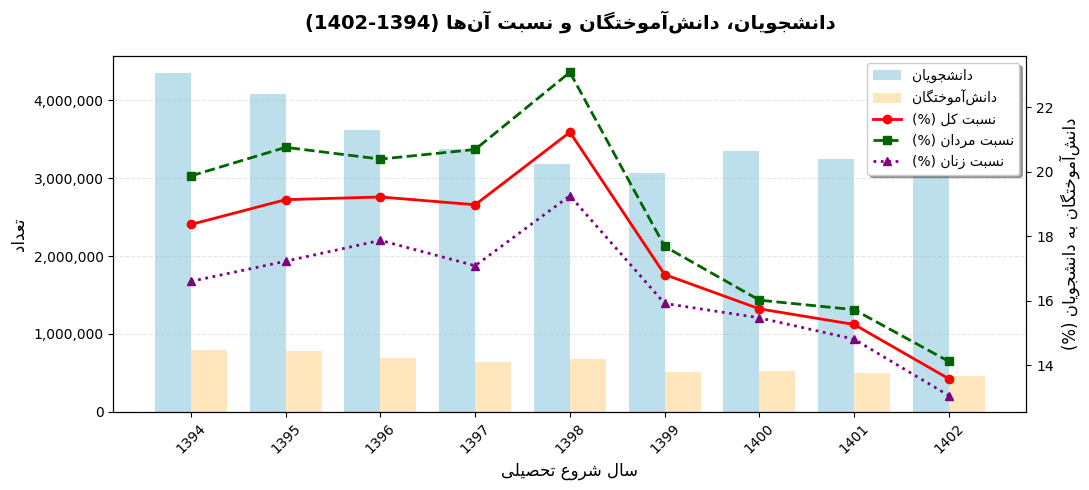

In [ ]:
# ۳. نمودار: میله‌ها = تعداد دانشجو و دانش‌آموخته ، خطوط = نسبت‌ها
fig, ax1 = plt.subplots(figsize=(11, 5))
x = np.arange(len(compare_df))
w = 0.38

b1 = ax1.bar(x - w/2, compare_df['کل_دانشجو'], w, color='lightblue', alpha=0.8,
             label=fix_persian_text('دانشجویان'))
b2 = ax1.bar(x + w/2, compare_df['کل_فارغ'], w, color='moccasin', alpha=0.9,
             label=fix_persian_text('دانش‌آموختگان'))
ax1.set_xticks(x)
ax1.set_xticklabels(compare_df['سال'], rotation=45)
ax1.set_xlabel(fix_persian_text('سال شروع تحصیلی'), fontsize=12)
ax1.set_ylabel(fix_persian_text('تعداد'), fontsize=12)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))

ax2 = ax1.twinx()
l1, = ax2.plot(x, compare_df['نسبت_کل'], marker='o', color='red', linewidth=2,
               label=fix_persian_text('نسبت کل (%)'))
l2, = ax2.plot(x, compare_df['نسبت_مرد'], marker='s', color='darkgreen', linewidth=2, linestyle='--',
               label=fix_persian_text('نسبت مردان (%)'))
l3, = ax2.plot(x, compare_df['نسبت_زن'], marker='^', color='purple', linewidth=2, linestyle=':',
               label=fix_persian_text('نسبت زنان (%)'))
ax2.set_ylabel(fix_persian_text('دانش‌آموختگان به دانشجویان (%)'), fontsize=12)

plt.title(fix_persian_text('دانشجویان، دانش‌آموختگان و نسبت آن‌ها (1394-1402)'), fontsize=14, fontweight='bold', pad=20)
handles = [b1, b2, l1, l2, l3]
ax1.legend(handles, [h.get_label() for h in handles], loc='upper right', frameon=True, shadow=True)
ax1.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# داشبورد

## کدهای داشبورد

In [4]:
from IPython.display import HTML, display
import json

# داده‌های دقیق استخراج‌شده از تمامی ۱۵ جدول شیت «جمعیت و نیروی انسانی»
data_payload = {
    # جدول ۱: پیش‌بینی جمعیت (۱۳۹۶ تا ۱۴۱۵)
    "pop_years": [1396, 1397, 1398, 1399, 1400, 1401, 1402, 1403, 1404, 1405, 1406, 1407, 1408, 1409, 1410, 1411, 1412, 1413, 1414, 1415],
    "pop_total": [81053, 81962, 82710, 83409, 84055, 84700, 85329, 85961, 86562, 87134, 87676, 88190, 88678, 89141, 89580, 89996, 90391, 90765, 91116, 91446],
    "pop_urban": [60304, 61311, 62201, 63056, 63876, 64655, 65427, 66207, 66968, 67708, 68361, 68994, 69608, 70203, 70782, 71307, 71816, 72309, 72784, 73243],
    "pop_rural": [20749, 20652, 20509, 20353, 20179, 20045, 19902, 19754, 19595, 19426, 19315, 19196, 19071, 18938, 18799, 18689, 18575, 18456, 18332, 18203],

    # جدول ۲: بعد خانوار (۱۳۳۵ تا ۱۴۰۰)
    "hh_years": [1335, 1345, 1355, 1365, 1370, 1375, 1385, 1390, 1395, 1400],
    "hh_total": [4.8, 5.0, 5.0, 5.1, 5.2, 4.8, 4.0, 3.5, 3.3, 3.19],
    "hh_urban": [4.7, 4.9, 4.8, 4.8, 4.9, 4.6, 3.9, 3.5, 3.3, 3.13],
    "hh_rural": [4.8, 5.0, 5.2, 5.4, 5.6, 5.1, 4.4, 3.7, 3.4, 3.36],

    # سال‌های مشترک جداول سالانه (۱۳۹۵ تا ۱۴۰۴)
    "years_95_04": [1395, 1396, 1397, 1398, 1399, 1400, 1401, 1402, 1403, 1404],

    # جدول ۳ و ۴: ولادت و وفات
    "births_total": [1528053, 1487923, 1366519, 1196132, 1114115, 1116212, 1075231, 1057964, 979929, 892278],
    "deaths_total": [369751, 376731, 376953, 395319, 511881, 544517, 418781, 442142, 458858, 459984],

    # جدول ۵: ازدواج و طلاق
    "marriages": [704716, 612237, 556315, 536636, 563567, 573789, 527871, 484861, 472590, 431664],
    "divorces": [181049, 182913, 179700, 179217, 188187, 205284, 208385, 206477, 197172, 181327],

    # جدول ۶: جمعیت ۱۵ ساله و بیشتر (هزار نفر)
    "labor_active": [25723, 26504, 26986, 27168, 25737, 25822, 26065, 26638, 26818, 26837],
    "labor_emp": [22525, 23297, 23731, 24274, 23263, 23447, 23716, 24490, 24788, 24822],
    "labor_unemp": [3198, 3207, 3255, 2894, 2474, 2375, 2349, 2148, 2030, 2014],

    # جدول ۷ و ۱۱: نرخ مشارکت اقتصادی و نسبت اشتغال (%)
    "part_total": [43.2, 44.2, 44.5, 44.1, 41.3, 40.9, 40.9, 41.3, 41.0, 40.6],
    "part_men": [70.4, 70.9, 71.6, 71.1, 68.7, 68.7, 68.2, 68.4, 68.1, 67.9],
    "part_women": [16.3, 17.4, 17.6, 17.0, 13.9, 13.3, 13.6, 14.2, 14.1, 13.4],
    "emp_ratio_total": [37.8, 38.9, 39.1, 39.4, 37.3, 37.2, 37.2, 37.9, 37.9, 37.5],

    # جدول ۸، ۹ و ۱۰: نرخ‌های بیکاری کل، جوانان ۱۵-۲۴ و سنین ۱۸-۳۵ (%)
    "unemp_total": [12.4, 12.1, 12.1, 10.7, 9.6, 9.2, 9.0, 8.1, 7.6, 7.5],
    "unemp_women": [20.7, 19.9, 18.9, 17.5, 15.6, 16.0, 15.8, 15.0, 14.3, 15.0],
    "youth_unemp_total": [29.2, 28.2, 27.7, 26.0, 23.7, 23.7, 22.6, 21.2, 20.1, 20.3],
    "youth_unemp_women": [44.2, 43.3, 40.1, 38.8, 36.0, 37.0, 36.1, 31.8, 30.4, 33.2],
    "age18_35_unemp_total": [26.8, 19.7, 19.6, 17.9, 16.7, 16.5, 16.3, 15.2, 14.7, 15.0],
    "age18_35_unemp_women": [41.2, 33.0, 31.6, 29.7, 27.9, 28.3, 27.8, 26.0, 24.9, 26.0],

    # جدول ۱۲: سهم بخش‌های اقتصادی (%)
    "sec_agri": [17.9, 17.5, 17.7, 17.7, 17.4, 16.3, 14.8, 14.4, 13.9, 13.9],
    "sec_ind": [31.9, 32.0, 32.0, 32.0, 33.3, 33.8, 33.6, 33.7, 33.3, 32.8],
    "sec_serv": [50.2, 50.5, 50.3, 50.3, 49.3, 49.8, 51.6, 51.9, 52.7, 53.2],

    # جدول ۱۳: دانش‌آموزان (۱۳۹۰ تا ۱۴۰۳)
    "sch_years": [1390, 1391, 1392, 1393, 1394, 1395, 1396, 1397, 1398, 1399, 1400, 1401, 1402, 1403],
    "sch_boys": [6932408, 6861311, 6964461, 7064602, 7174229, 7349326, 7599675, 8001045, 8137984, 8073596, 8424777, 8713472, 8452612, 8639835],
    "sch_girls": [6418846, 6365162, 6441997, 6550709, 6687672, 6871016, 7100634, 7461001, 7636091, 7592991, 7947088, 8524006, 8053881, 8222213],

    # جدول ۱۴ و ۱۵: دانشجویان و دانش‌آموختگان
    "uni_years": [1394, 1395, 1396, 1397, 1398, 1399, 1400, 1401, 1402, 1403],
    "uni_men": [2345824, 2202231, 1930954, 1768931, 1638746, 1556792, 1700794, 1618505, 1651073, 1684930],
    "uni_women": [2002559, 1871596, 1685160, 1604457, 1544243, 1513956, 1641426, 1631096, 1700804, 1818249],
    "grad_years": [1394, 1395, 1396, 1397, 1398, 1399, 1400, 1401, 1402],
    "grad_total": [798736, 779646, 695055, 640262, 675724, 516416, 526520, 496172, 455335],
    "grad_ratio": [18.37, 19.14, 19.22, 18.98, 21.23, 16.82, 15.75, 15.27, 13.58],
    "fields_labels": ["علوم انسانی", "فنی و مهندسی", "پزشکی", "هنر", "علوم پایه", "کشاورزی و دامپزشکی"],
    "fields_uni_men": [775928, 582615, 130314, 75896, 67519, 52658],
    "fields_uni_women": [1060845, 191819, 186301, 173298, 148016, 57970],
    "fields_grad_men": [113497, 79745, 15530, 8886, 8519, 6979],
    "fields_grad_women": [128243, 24656, 22920, 23657, 15986, 6717]
}

dashboard_html = f"""
<!DOCTYPE html>
<html lang="fa" dir="rtl">
<head>
    <meta charset="UTF-8">
    <title>داشبورد جامع شاخص‌های کلان ایران</title>
    <link href="https://cdn.jsdelivr.net/gh/rastikerdar/vazirmatn@v33.003/Vazirmatn-font-face.css" rel="stylesheet" type="text/css" />
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        * {{ box-sizing: border-box; }}
        .db-container {{
            font-family: 'Vazirmatn', Tahoma, sans-serif;
            background-color: #f1f5f9;
            color: #1e293b;
            padding: 24px;
            border-radius: 16px;
            direction: rtl;
            text-align: right;
            max-width: 1320px;
            margin: 10px auto;
            box-shadow: 0 10px 30px rgba(0,0,0,0.08);
        }}
        .db-top-bar {{
            background: linear-gradient(135deg, #0f172a 0%, #1e3a8a 100%);
            color: #fff;
            padding: 24px 28px;
            border-radius: 14px;
            margin-bottom: 20px;
            display: flex;
            justify-content: space-between;
            align-items: center;
            flex-wrap: wrap;
            gap: 16px;
        }}
        .db-top-bar h1 {{ margin: 0 0 6px 0; font-size: 22px; font-weight: 800; color: #fff; }}
        .db-top-bar p {{ margin: 0; font-size: 13.5px; color: #cbd5e1; }}
        .db-tabs {{
            display: flex;
            gap: 10px;
            margin-bottom: 22px;
            flex-wrap: wrap;
            background: #e2e8f0;
            padding: 6px;
            border-radius: 12px;
        }}
        .db-tab-btn {{
            font-family: 'Vazirmatn', Tahoma, sans-serif;
            border: none;
            background: transparent;
            color: #475569;
            padding: 10px 20px;
            border-radius: 8px;
            font-size: 13.5px;
            font-weight: 700;
            cursor: pointer;
            transition: all 0.2s;
        }}
        .db-tab-btn.active {{
            background: #ffffff;
            color: #1e3a8a;
            box-shadow: 0 2px 6px rgba(0,0,0,0.08);
        }}
        .db-tab-btn:hover:not(.active) {{ background: rgba(255,255,255,0.5); }}

        .kpi-grid {{
            display: grid;
            grid-template-columns: repeat(auto-fit, minmax(220px, 1fr));
            gap: 14px;
            margin-bottom: 24px;
        }}
        .kpi-box {{
            background: #fff;
            padding: 16px 18px;
            border-radius: 12px;
            border-right: 5px solid #3b82f6;
            box-shadow: 0 2px 5px rgba(0,0,0,0.04);
        }}
        .kpi-label {{ font-size: 12px; color: #64748b; font-weight: 600; margin-bottom: 6px; }}
        .kpi-num {{ font-size: 21px; font-weight: 800; color: #0f172a; margin-bottom: 6px; }}
        .kpi-tag {{ font-size: 11px; padding: 2px 8px; border-radius: 6px; font-weight: 600; display: inline-block; }}
        .t-red {{ background: #fee2e2; color: #b91c1c; }}
        .t-green {{ background: #dcfce7; color: #15803d; }}
        .t-amber {{ background: #fef3c7; color: #b45309; }}
        .t-blue {{ background: #e0f2fe; color: #0369a1; }}

        .section-block {{ margin-bottom: 28px; }}
        .section-header {{
            font-size: 17px;
            font-weight: 800;
            color: #0f172a;
            margin: 0 0 14px 0;
            padding-right: 12px;
            border-right: 4px solid #1e3a8a;
        }}
        .charts-grid {{
            display: grid;
            grid-template-columns: repeat(auto-fit, minmax(480px, 1fr));
            gap: 18px;
        }}
        .chart-card {{
            background: #fff;
            padding: 18px 20px;
            border-radius: 12px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.04);
        }}
        .chart-card h4 {{
            margin: 0 0 6px 0;
            font-size: 14.5px;
            color: #1e293b;
        }}
        .chart-card p.sub-note {{
            margin: 0 0 12px 0;
            font-size: 11.5px;
            color: #64748b;
            border-bottom: 1px solid #f1f5f9;
            padding-bottom: 8px;
        }}
        .canvas-wrap {{ position: relative; height: 260px; width: 100%; }}
    </style>
</head>
<body>
<div class="db-container">
    <div class="db-top-bar">
        <div>
            <h1>📊 داشبورد جامع تحلیل شاخص‌های کلان ایران (۱۵ جدول رسمی)</h1>
            <p>مصورسازی تعاملی داده‌های جمعیت، خانواده، بازار کار و آموزش عالی | مینی‌پروژه تحلیل داده با پایتون</p>
        </div>
        <div style="background:rgba(255,255,255,0.15); padding:8px 16px; border-radius:99px; font-size:12.5px;">
            تعداد نمودارها: ۱۲ نمودار تعاملی
        </div>
    </div>

    <!-- دکمه‌های تب‌بندی -->
    <div class="db-tabs">
        <button class="db-tab-btn active" onclick="filterSection('all', this)">🌐 نمایش همه‌ی بخش‌ها (۱۲ نمودار)</button>
        <button class="db-tab-btn" onclick="filterSection('sec-pop', this)">👨‍👩‍👧‍👦 الف) جمعیت و خانواده (۴ نمودار)</button>
        <button class="db-tab-btn" onclick="filterSection('sec-labor', this)">👷 ب) بازار کار و اشتغال (۴ نمودار)</button>
        <button class="db-tab-btn" onclick="filterSection('sec-edu', this)">🎓 ج) آموزش و دانشگاه (۴ نمودار)</button>
    </div>

    <!-- ۸ کارت شاخص کلیدی (KPI) -->
    <div class="kpi-grid">
        <div class="kpi-box" style="border-right-color:#2563eb;">
            <div class="kpi-label">جمعیت کل کشور (۱۴۰۴ ← ۱۴۱۵)</div>
            <div class="kpi-num">۸۶.۵۶ ← ۹۱.۴۵ میلیون</div>
            <span class="kpi-tag t-blue">افت نرخ رشد سالانه به ۰.۳۶٪ در ۱۴۱۵</span>
        </div>
        <div class="kpi-box" style="border-right-color:#0891b2;">
            <div class="kpi-label">متوسط بعد خانوار (۱۳۷۰ ← ۱۴۰۰)</div>
            <div class="kpi-num">۵.۲۰ ← ۳.۱۹ نفر</div>
            <span class="kpi-tag t-blue">شهری: ۳.۱۳ نفر | روستایی: ۳.۳۶ نفر</span>
        </div>
        <div class="kpi-box" style="border-right-color:#dc2626;">
            <div class="kpi-label">تعداد موالید ثبت‌شده (۱۴۰۴)</div>
            <div class="kpi-num">۸۹۲,۲۷۸ تولد</div>
            <span class="kpi-tag t-red">▼ ۴۱.۶٪ کاهش نسبت به ۱۳۹۵ (۱.۵۳ میلیون)</span>
        </div>
        <div class="kpi-box" style="border-right-color:#d97706;">
            <div class="kpi-label">ازدواج و طلاق ثبت‌شده (۱۴۰۴)</div>
            <div class="kpi-num">۴۳۱ هزار ازدواج</div>
            <span class="kpi-tag t-amber">۱۸۱ هزار طلاق (۲.۴ ازدواج به ازای هر طلاق)</span>
        </div>
        <div class="kpi-box" style="border-right-color:#059669;">
            <div class="kpi-label">مشارکت اقتصادی و نسبت اشتغال (۱۴۰۴)</div>
            <div class="kpi-num">۴۰.۶٪ مشارکت</div>
            <span class="kpi-tag t-amber">نسبت اشتغال: ۳۷.۵٪ (زنان فقط ۱۱.۴٪)</span>
        </div>
        <div class="kpi-box" style="border-right-color:#7c3aed;">
            <div class="kpi-label">نرخ بیکاری کل و جوانان (۱۴۰۴)</div>
            <div class="kpi-num">۷.۵٪ کل | ۲۰.۳٪ جوانان</div>
            <span class="kpi-tag t-red">بیکاری دختران جوان (۱۵-۲۴): ۳۳.۲٪</span>
        </div>
        <div class="kpi-box" style="border-right-color:#4f46e5;">
            <div class="kpi-label">جمعیت دانش‌آموزی کشور (۰۴-۱۴۰۳)</div>
            <div class="kpi-num">۱۶.۸۶ میلیون نفر</div>
            <span class="kpi-tag t-green">پسران: ۵۱.۲٪ | دختران: ۴۸.۸٪</span>
        </div>
        <div class="kpi-box" style="border-right-color:#db2777;">
            <div class="kpi-label">دانشجویان و فارغ‌التحصیلان عالی</div>
            <div class="kpi-num">۳.۵۰ میلیون دانشجو</div>
            <span class="kpi-tag t-blue">۵۱.۹٪ زن | ۵۲.۴٪ در رشته علوم انسانی</span>
        </div>
    </div>

    <!-- بخش الف: جمعیت و خانواده -->
    <div id="sec-pop" class="section-block">
        <h3 class="section-header">الف) تحلیل شاخص‌های جمعیتی و پویایی خانواده (جداول ۱ تا ۵)</h3>
        <div class="charts-grid">
            <div class="chart-card">
                <h4>۱. پیش‌بینی جمعیت کل کشور، شهر و روستا (۱۳۹۶ تا ۱۴۱۵)</h4>
                <p class="sub-note">جدول ۱: رشد جمعیت شهری از ۶۰.۳ به ۷۳.۲ میلیون و کاهش جمعیت روستایی از ۲۰.۷ به ۱۸.۲ میلیون نفر</p>
                <div class="canvas-wrap"><canvas id="c_pop"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۲. روند تاریخی متوسط تعداد افراد در خانوار (۱۳۳۵ تا ۱۴۰۰)</h4>
                <p class="sub-note">جدول ۲: رسیدن به اوج ۵.۲ نفر در سال ۱۳۷۰ و سقوط پیوسته تا ۳.۱۹ نفر در سال ۱۴۰۰</p>
                <div class="canvas-wrap"><canvas id="c_hh"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۳. مقایسه روند ولادت و وفات ثبت‌شده (۱۳۹۵ تا ۱۴۰۴)</h4>
                <p class="sub-note">جداول ۳ و ۴: افت شدید موالید و جهش وفات در سال‌های ۱۳۹۹ و ۱۴۰۰ (همه‌گیری کرونا)</p>
                <div class="canvas-wrap"><canvas id="c_vital"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۴. روند ازدواج و طلاق ثبت‌شده در کشور (۱۳۹۵ تا ۱۴۰۴)</h4>
                <p class="sub-note">جدول ۵: کاهش ۳۸.۷ درصدی ازدواج در یک دهه و رشد مقطعی در سال‌های ۱۳۹۹ و ۱۴۰۰</p>
                <div class="canvas-wrap"><canvas id="c_mar"></canvas></div>
            </div>
        </div>
    </div>

    <!-- بخش ب: بازار کار و اشتغال -->
    <div id="sec-labor" class="section-block">
        <h3 class="section-header">ب) تحلیل شاخص‌های بازار کار، اشتغال و بیکاری (جداول ۶ تا ۱۲)</h3>
        <div class="charts-grid">
            <div class="chart-card">
                <h4>۵. جمعیت فعال، شاغل و بیکار ۱۵ ساله و بیشتر (هزار نفر)</h4>
                <p class="sub-note">جدول ۶: افت ۱.۴۳ میلیون نفری جمعیت فعال در سال ۱۳۹۹ و رشد کند شاغلان</p>
                <div class="canvas-wrap"><canvas id="c_labor_abs"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۶. نرخ مشارکت اقتصادی به تفکیک جنسیت و نسبت اشتغال کل (%)</h4>
                <p class="sub-note">جداول ۷ و ۱۱: شکاف ۵۴ درصدی مشارکت مردان (۶۷.۹٪) و زنان (۱۳.۴٪) در سال ۱۴۰۴</p>
                <div class="canvas-wrap"><canvas id="c_part"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۷. مقایسه نرخ بیکاری در گروه‌های سنی مختلف و زنان (%)</h4>
                <p class="sub-note">جداول ۸، ۹ و ۱۰: نرخ بیکاری بسیار بالای جوانان ۱۵-۲۴ سال (۲۰.۳٪) و زنان جوان (۳۳.۲٪)</p>
                <div class="canvas-wrap"><canvas id="c_unemp_all"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۸. روند سهم بخش‌های عمده اقتصادی از کل اشتغال کشور (%)</h4>
                <p class="sub-note">جدول ۱۲: کاهش مستمر سهم کشاورزی (از ۱۷.۹٪ به ۱۳.۹٪) و افزایش سهم خدمات به ۵۳.۲٪</p>
                <div class="canvas-wrap"><canvas id="c_sectors"></canvas></div>
            </div>
        </div>
    </div>

    <!-- بخش ج: آموزش و تحصیلات عالی -->
    <div id="sec-edu" class="section-block">
        <h3 class="section-header">ج) تحلیل شاخص‌های آموزش مدرسه‌ای و آموزش عالی (جداول ۱۳ تا ۱۵)</h3>
        <div class="charts-grid">
            <div class="chart-card">
                <h4>۹. روند تعداد دانش‌آموزان پسر و دختر (۱۳۹۰ تا ۱۴۰۳)</h4>
                <p class="sub-note">جدول ۱۳: افزایش ۳.۷ میلیونی دانش‌آموزان در دهه نود و رسیدن به فلات ۱۶.۸۶ میلیون نفر</p>
                <div class="canvas-wrap"><canvas id="c_school"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۱۰. روند تعداد دانشجویان به تفکیک جنسیت (۱۳۹۴ تا ۱۴۰۳)</h4>
                <p class="sub-note">جدول ۱۴: عبور از کف ۳.۰۷ میلیون دانشجو در ۱۳۹۹ و پیشی گرفتن تعداد دانشجویان زن از ۱۴۰۱</p>
                <div class="canvas-wrap"><canvas id="c_uni_trend"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۱۱. توزیع دانشجویان بر حسب گروه رشته و جنسیت (سال ۰۴-۱۴۰۳)</h4>
                <p class="sub-note">جدول ۱۴: تمرکز ۵۲.۴٪ دانشجویان در علوم انسانی و غلبه مردان در فنی و مهندسی (۷۵٪)</p>
                <div class="canvas-wrap"><canvas id="c_fields"></canvas></div>
            </div>
            <div class="chart-card">
                <h4>۱۲. روند تعداد دانش‌آموختگان و نسبت فارغ‌التحصیلی به کل دانشجویان</h4>
                <p class="sub-note">مقایسه جداول ۱۴ و ۱۵: کاهش ۴۳ درصدی فارغ‌التحصیلان و افت نرخ فارغ‌التحصیلی به ۱۳.۶٪</p>
                <div class="canvas-wrap"><canvas id="c_grads"></canvas></div>
            </div>
        </div>
    </div>
</div>

<script>
    const D = {json.dumps(data_payload, ensure_ascii=False)};
    Chart.defaults.font.family = "'Vazirmatn', Tahoma, sans-serif";
    Chart.defaults.color = '#475569';
    const commonOpts = {{ responsive: true, maintainAspectRatio: false, interaction: {{ mode: 'index', intersect: false }} }};

    // ۱. پیش‌بینی جمعیت
    new Chart(document.getElementById('c_pop'), {{
        type: 'line',
        data: {{
            labels: D.pop_years,
            datasets: [
                {{ label: 'کل کشور (هزار نفر)', data: D.pop_total, borderColor: '#1e3a8a', borderWidth: 2.5, tension: 0.2 }},
                {{ label: 'مناطق شهری', data: D.pop_urban, borderColor: '#0284c7', borderWidth: 2, borderDash: [5,5], tension: 0.2 }},
                {{ label: 'مناطق روستایی', data: D.pop_rural, borderColor: '#d97706', borderWidth: 2, tension: 0.2 }}
            ]
        }},
        options: commonOpts
    }});

    // ۲. بعد خانوار
    new Chart(document.getElementById('c_hh'), {{
        type: 'line',
        data: {{
            labels: D.hh_years,
            datasets: [
                {{ label: 'کل کشور', data: D.hh_total, borderColor: '#ef4444', borderWidth: 2.5, tension: 0.2 }},
                {{ label: 'شهری', data: D.hh_urban, borderColor: '#3b82f6', borderWidth: 2, borderDash: [4,4], tension: 0.2 }},
                {{ label: 'روستایی', data: D.hh_rural, borderColor: '#10b981', borderWidth: 2, tension: 0.2 }}
            ]
        }},
        options: commonOpts
    }});

    // ۳. ولادت و وفات
    new Chart(document.getElementById('c_vital'), {{
        type: 'line',
        data: {{
            labels: D.years_95_04,
            datasets: [
                {{ label: 'تعداد ولادت', data: D.births_total, borderColor: '#10b981', backgroundColor: 'rgba(16,185,129,0.1)', fill: true, borderWidth: 2.5, tension: 0.3 }},
                {{ label: 'تعداد وفات', data: D.deaths_total, borderColor: '#ef4444', backgroundColor: 'rgba(239,68,68,0.1)', fill: true, borderWidth: 2.5, borderDash: [5,5], tension: 0.3 }}
            ]
        }},
        options: commonOpts
    }});

    // ۴. ازدواج و طلاق
    new Chart(document.getElementById('c_mar'), {{
        type: 'bar',
        data: {{
            labels: D.years_95_04,
            datasets: [
                {{ label: 'ازدواج', data: D.marriages, backgroundColor: '#3b82f6', borderRadius: 4 }},
                {{ label: 'طلاق', data: D.divorces, backgroundColor: '#f59e0b', borderRadius: 4 }}
            ]
        }},
        options: commonOpts
    }});

    // ۵. جمعیت فعال، شاغل و بیکار
    new Chart(document.getElementById('c_labor_abs'), {{
        type: 'bar',
        data: {{
            labels: D.years_95_04,
            datasets: [
                {{ label: 'جمعیت فعال (هزار نفر)', data: D.labor_active, type: 'line', borderColor: '#0f172a', borderWidth: 2.5, tension: 0.2 }},
                {{ label: 'جمعیت شاغل', data: D.labor_emp, backgroundColor: '#10b981', borderRadius: 4 }},
                {{ label: 'جمعیت بیکار', data: D.labor_unemp, backgroundColor: '#ef4444', borderRadius: 4 }}
            ]
        }},
        options: commonOpts
    }});

    // ۶. نرخ مشارکت و نسبت اشتغال
    new Chart(document.getElementById('c_part'), {{
        type: 'line',
        data: {{
            labels: D.years_95_04,
            datasets: [
                {{ label: 'مشارکت مردان (%)', data: D.part_men, borderColor: '#059669', borderWidth: 2.5, tension: 0.2 }},
                {{ label: 'مشارکت کل کشور (%)', data: D.part_total, borderColor: '#2563eb', borderWidth: 2.5, tension: 0.2 }},
                {{ label: 'نسبت اشتغال کل (%)', data: D.emp_ratio_total, borderColor: '#d97706', borderWidth: 2, borderDash: [4,4], tension: 0.2 }},
                {{ label: 'مشارکت زنان (%)', data: D.part_women, borderColor: '#9333ea', borderWidth: 2.5, tension: 0.2 }}
            ]
        }},
        options: commonOpts
    }});

    // ۷. مقایسه نرخ‌های بیکاری در گروه‌های سنی
    new Chart(document.getElementById('c_unemp_all'), {{
        type: 'line',
        data: {{
            labels: D.years_95_04,
            datasets: [
                {{ label: 'بیکاری زنان جوان ۱۵-۲۴ سال (%)', data: D.youth_unemp_women, borderColor: '#be185d', borderWidth: 2, borderDash: [3,3], tension: 0.2 }},
                {{ label: 'بیکاری کل جوانان ۱۵-۲۴ سال (%)', data: D.youth_unemp_total, borderColor: '#f59e0b', borderWidth: 2.5, tension: 0.2 }},
                {{ label: 'بیکاری کل سنین ۱۸-۳۵ سال (%)', data: D.age18_35_unemp_total, borderColor: '#6366f1', borderWidth: 2, tension: 0.2 }},
                {{ label: 'بیکاری کل جمعیت ۱۵+ (%)', data: D.unemp_total, borderColor: '#10b981', borderWidth: 2.5, tension: 0.2 }}
            ]
        }},
        options: commonOpts
    }});

    // ۸. سهم بخش‌های اقتصادی
    new Chart(document.getElementById('c_sectors'), {{
        type: 'bar',
        data: {{
            labels: D.years_95_04,
            datasets: [
                {{ label: 'خدمات (%)', data: D.sec_serv, backgroundColor: '#3b82f6' }},
                {{ label: 'صنعت (%)', data: D.sec_ind, backgroundColor: '#f59e0b' }},
                {{ label: 'کشاورزی (%)', data: D.sec_agri, backgroundColor: '#10b981' }}
            ]
        }},
        options: {{
            ...commonOpts,
            scales: {{ x: {{ stacked: true }}, y: {{ stacked: true, max: 100 }} }}
        }}
    }});

    // ۹. دانش‌آموزان پسر و دختر
    new Chart(document.getElementById('c_school'), {{
        type: 'bar',
        data: {{
            labels: D.sch_years,
            datasets: [
                {{ label: 'پسران', data: D.sch_boys, backgroundColor: '#3b82f6', borderRadius: 3 }},
                {{ label: 'دختران', data: D.sch_girls, backgroundColor: '#f43f5e', borderRadius: 3 }}
            ]
        }},
        options: commonOpts
    }});

    // ۱۰. روند دانشجویان مرد و زن
    new Chart(document.getElementById('c_uni_trend'), {{
        type: 'line',
        data: {{
            labels: D.uni_years,
            datasets: [
                {{ label: 'دانشجویان زن', data: D.uni_women, borderColor: '#ec4899', backgroundColor: 'rgba(236,72,153,0.08)', fill: true, borderWidth: 2.5, tension: 0.3 }},
                {{ label: 'دانشجویان مرد', data: D.uni_men, borderColor: '#2563eb', backgroundColor: 'rgba(37,99,235,0.08)', fill: true, borderWidth: 2.5, borderDash: [5,5], tension: 0.3 }}
            ]
        }},
        options: commonOpts
    }});

    // ۱۱. تفکیک رشته‌های دانشگاهی
    new Chart(document.getElementById('c_fields'), {{
        type: 'bar',
        data: {{
            labels: D.fields_labels,
            datasets: [
                {{ label: 'مردان (۰۴-۱۴۰۳)', data: D.fields_uni_men, backgroundColor: '#3b82f6', borderRadius: 4 }},
                {{ label: 'زنان (۰۴-۱۴۰۳)', data: D.fields_uni_women, backgroundColor: '#ec4899', borderRadius: 4 }}
            ]
        }},
        options: {{
            indexAxis: 'y',
            responsive: true,
            maintainAspectRatio: false,
            scales: {{ x: {{ stacked: true }}, y: {{ stacked: true }} }}
        }}
    }});

    // ۱۲. فارغ‌التحصیلان و نسبت فارغ‌التحصیلی
    new Chart(document.getElementById('c_grads'), {{
        type: 'bar',
        data: {{
            labels: D.grad_years,
            datasets: [
                {{ label: 'تعداد دانش‌آموختگان', data: D.grad_total, backgroundColor: '#8b5cf6', borderRadius: 4, yAxisID: 'y' }},
                {{ label: 'نسبت به کل دانشجویان (%)', data: D.grad_ratio, type: 'line', borderColor: '#ef4444', borderWidth: 2.5, yAxisID: 'y1', tension: 0.2 }}
            ]
        }},
        options: {{
            ...commonOpts,
            scales: {{
                y: {{ type: 'linear', position: 'right', title: {{ display: true, text: 'تعداد نفر' }} }},
                y1: {{ type: 'linear', position: 'left', grid: {{ drawOnChartArea: false }}, title: {{ display: true, text: 'درصد (%)' }} }}
            }}
        }}
    }});

    // تابع فیلتر تب‌ها
    function filterSection(secId, btn) {{
        document.querySelectorAll('.db-tab-btn').forEach(b => b.classList.remove('active'));
        btn.classList.add('active');
        const sections = ['sec-pop', 'sec-labor', 'sec-edu'];
        sections.forEach(id => {{
            document.getElementById(id).style.display = (secId === 'all' || secId === id) ? 'block' : 'none';
        }});
    }}
</script>
</body>
</html>
"""

# ذخیره فایل مستقل HTML و دانلود خودکار در صورت اجرا در کولب
filename = "iran_comprehensive_dashboard.html"
with open(filename, "w", encoding="utf-8") as f:
    f.write(dashboard_html)



try:
    from google.colab import files
    files.download(filename)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## مشاهده داشبرد

In [5]:
display(HTML(dashboard_html))